# Ejercicios UD1 · Bloque 3 — Calidad de datos

**Módulo:** Depuración, Limpieza y Clasificación de Datos (5109)
**Unidad Didáctica:** UD1 — Análisis exploratorio de datos: estructura, variables y calidad
**Alumno/a: Alejandro Suárez Durán**
**Fecha de entrega:**

---

Este cuaderno recoge los ejercicios del **Bloque 3** de la UD1. Están organizados por sesiones, igual que los cuadernos de teoría:

| Sesión | Cuaderno de teoría | Ejercicios |
|---|---|---|
| 1 | `B3_S1_Valores_Ausentes_y_Outliers` | 1.1 – 1.5 |
| 2 | `B3_S2_Datos_Incorrectos_y_Cobertura` | 2.1 – 2.6 |

Seguimos con los pacientes de **enfermedad cardiaca** del Bloque 2, donde dejamos pendiente una tarea: en el ejercicio 3.4 apuntaste los problemas de calidad «que hay que tratar en el Bloque 3». Ahora toca diagnosticarlos a fondo.

- En la **Sesión 1** trabajas con `heart.csv`, el mismo fichero del Bloque 2: valores ausentes disfrazados, mecanismos de ausencia y valores atípicos.
- En la **Sesión 2** trabajas con `heart_sucio.csv`: los **mismos pacientes**, pero tal como llegarían si tres centros sanitarios exportaran sus registros cada uno a su manera. Tendrás que cargarlo, encontrar los errores, corregirlos y dejar un dataset limpio y documentado.

Algunos ejercicios son preguntas de reflexión (responde en la celda de texto) y otros son de código (escribe tu solución donde pone `TODO`). Los ejercicios se encadenan: los DataFrames que preparas en un ejercicio se usan en los siguientes.

> **Antes de empezar:** copia este cuaderno a tu carpeta `mis_cuadernos/` y trabaja sobre la copia, así `git pull` no te dará conflictos. Copia también la carpeta `datos/` (o ajusta la ruta `DATOS` de la celda de carga).
>
> **Cómo entregar:** reinicia el kernel y ejecuta todas las celdas (**Restart** → **Run All**), comprueba que no hay errores, guarda y sube el fichero `.ipynb` al aula virtual. Sube también los dos CSV que genera el ejercicio 2.6.

## Criterios de evaluación

Esta relación de ejercicios evalúa los siguientes criterios de evaluación del módulo (Real Decreto 183/2026, redacción literal):

> **RA1.** Identifica la estructura y variables en los datos en el dominio de aplicación, así como su cobertura y calidad del conjunto, aplicando técnicas exploratorias mediante análisis exploratorios de datos (AED) para la selección de atributos clave en el entrenamiento posterior.

| CE | Criterio de evaluación | Ejercicios |
|:--:|------------------------|:----------:|
| **1.b** | Se han detectado datos incorrectamente introducidos, ausencia de valores, una mala codificación de las variables o valores atípicos. | Todos |
| **1.c** | Se han identificado la estructura, variables y relaciones de los conjuntos de datos aplicando técnicas exploratorias. | 1.2, 1.3, 1.5, 2.5 |
| **1.d** | Se han identificado entidades, volumetrías, relaciones y atributos, para documentar cada conjunto de datos, describiendo sus características. | 2.1, 2.2, 2.5, 2.6 |

In [43]:
# Librerías que se usan en todo el cuaderno
import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats
from pandas.api.types import CategoricalDtype

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

print('✅ Librerías cargadas')

✅ Librerías cargadas


## Los datos

`heart.csv` es el dataset **Heart Failure Prediction** que ya conoces del Bloque 2: 918 pacientes de cinco hospitales estudiados por sospecha de enfermedad cardiaca, con 11 variables clínicas y la variable objetivo `HeartDisease`. Si necesitas repasar el significado de las variables, vuelve a la tabla del cuaderno de ejercicios del Bloque 2.

La celda siguiente lo carga (y lo descarga si no lo tienes). Como en el Bloque 2:

> `heart_raw` es la copia **original** y no se toca en todo el cuaderno. Trabaja siempre sobre copias.

In [44]:
DATOS = Path('datos')
URL_HEART = 'https://raw.githubusercontent.com/imteekay/heart-failure-prediction/main/heart.csv'
ruta_heart = DATOS / 'heart.csv'

if not ruta_heart.exists():
    print('Descargando heart.csv...')
    DATOS.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL_HEART, ruta_heart)

heart_raw = pd.read_csv(ruta_heart)   # copia original: no la modifiques
heart = heart_raw.copy()              # copia de trabajo

NUMERICAS = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
print('✅ Dataset cargado:', heart.shape)

✅ Dataset cargado: (918, 12)


---
# Sesión 1 — Valores ausentes y valores atípicos

## Ejercicio 1.1 — Los ausentes que no se ven

En el Bloque 2 descubriste que `info()` decía «0 nulos» y, sin embargo, había pacientes con colesterol 0 mg/dL. Vamos a hacer el diagnóstico de ausentes completo.

**Parte A — Recuento.**

1. Cuenta los `NaN` por columna de `heart` con `isnull()`.
2. Decide en qué columnas numéricas un **0 es físicamente imposible** y guárdalas en una lista `COLS_CERO_IMPOSIBLE`. Revisa las cinco de `NUMERICAS` y también `FastingBS`.
3. Crea `heart_na`, una copia de `heart` en la que los ceros de esas columnas se sustituyan por `NaN`.
4. Construye una tabla con el número y el porcentaje de ausentes de las columnas de `heart_na` que tengan alguno, ordenada de mayor a menor.
5. Cuenta los ausentes **por fila**: ¿cuántas filas tienen 0, 1, 2… ausentes?

In [45]:
# TODO: NaN por columna en heart
print('NaN por columna en heart:')
print(heart.isnull().sum())
print()

# TODO: COLS_CERO_IMPOSIBLE = [...]
# Oldpeak y FastingBS no entran porque en ellas el 0 es un valor válido
COLS_CERO_IMPOSIBLE = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR']

# TODO: heart_na con los ceros imposibles como NaN
heart_na = heart.copy()
heart_na[COLS_CERO_IMPOSIBLE] = heart_na[COLS_CERO_IMPOSIBLE].replace(0, np.nan)

# TODO: tabla de ausentes (n y %) de heart_na
n_ausentes = heart_na.isnull().sum()
n_ausentes = n_ausentes[n_ausentes > 0]
tabla_ausentes = pd.DataFrame({
    'n': n_ausentes,
    'porcentaje': (n_ausentes / len(heart_na) * 100).round(2)
})
tabla_ausentes = tabla_ausentes.sort_values('n', ascending=False)
print('Ausentes en heart_na:')
print(tabla_ausentes)
print()

# TODO: ausentes por fila
print('Número de filas según sus ausentes:')
print(heart_na.isnull().sum(axis=1).value_counts().sort_index())

NaN por columna en heart:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Ausentes en heart_na:
               n  porcentaje
Cholesterol  172       18.74
RestingBP      1        0.11

Número de filas según sus ausentes:
0    746
1    171
2      1
Name: count, dtype: int64


**Parte B — Visualización con `missingno`.**
Dibuja, cada uno en su celda, `msno.matrix`, `msno.bar` y `msno.heatmap` de `heart_na`. Pon título a cada gráfico.

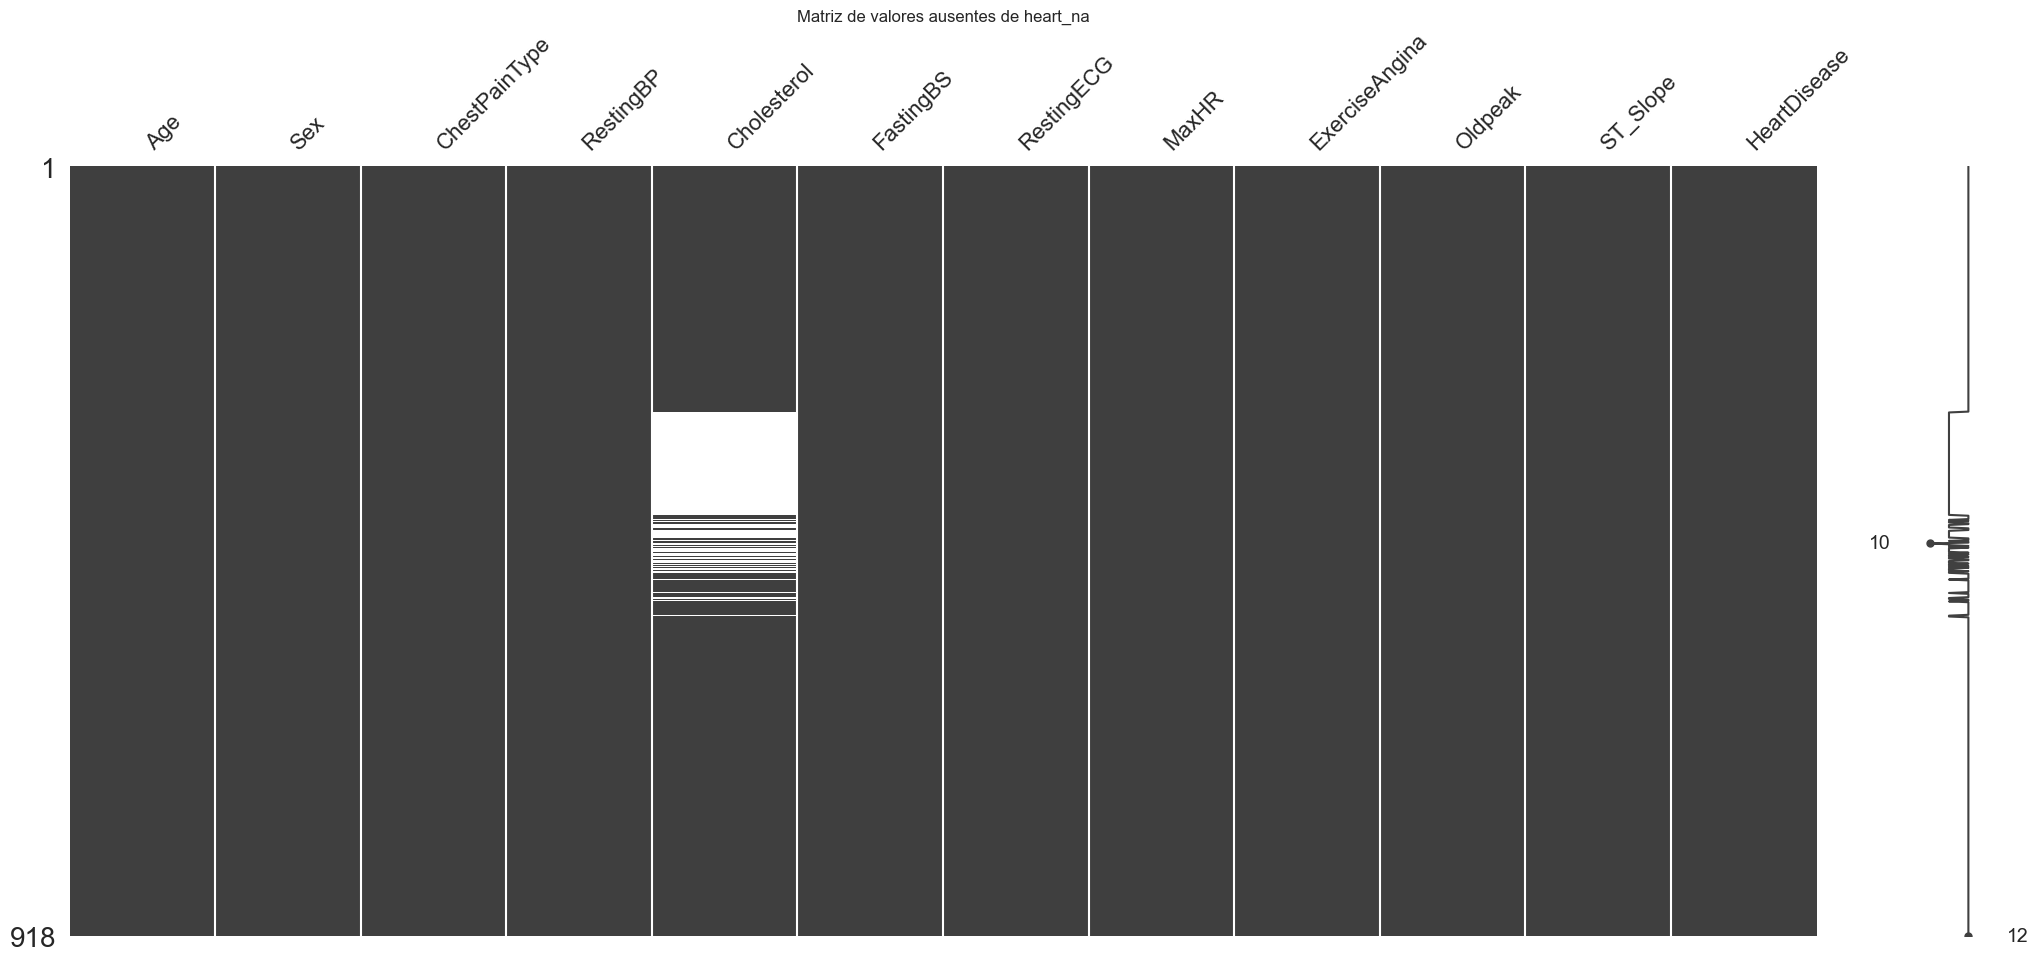

In [46]:
# TODO: msno.matrix
msno.matrix(heart_na)
plt.title('Matriz de valores ausentes de heart_na')
plt.show()

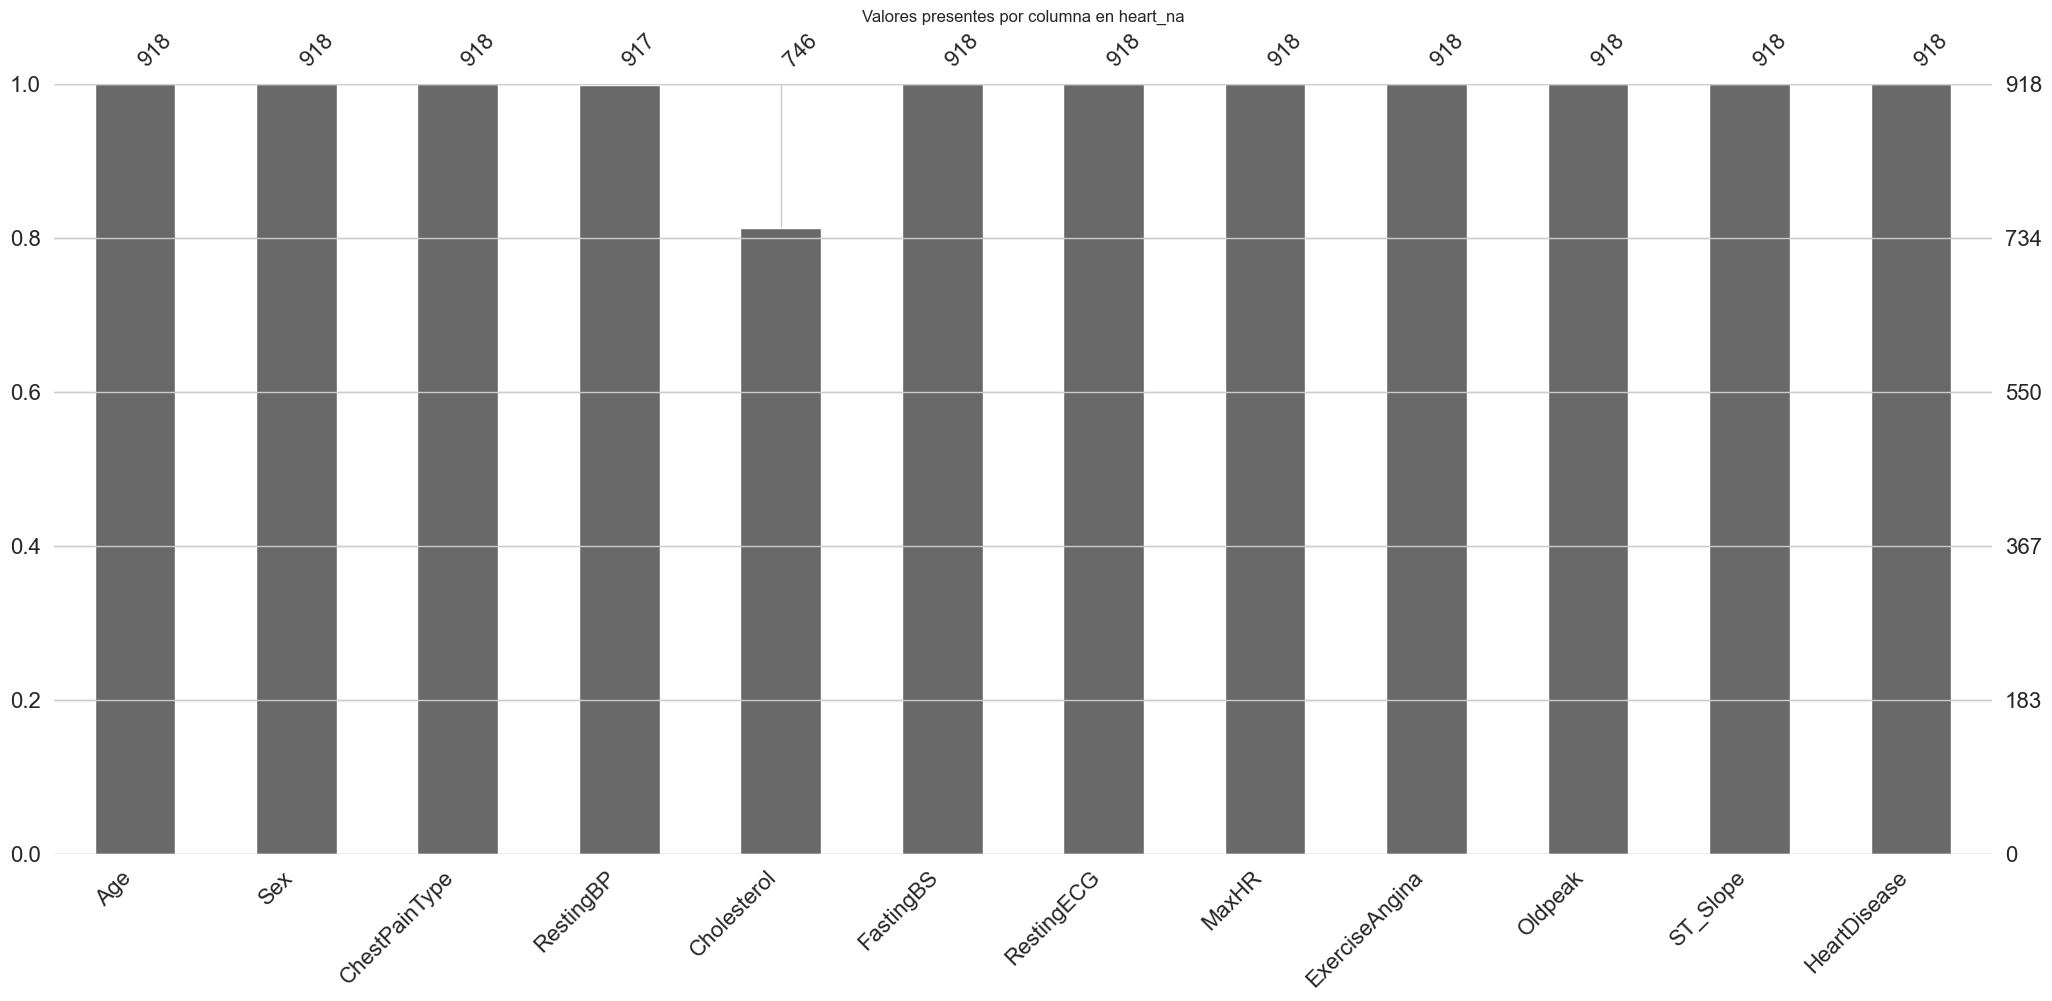

In [47]:
# TODO: msno.bar
msno.bar(heart_na)
plt.title('Valores presentes por columna en heart_na')
plt.show()

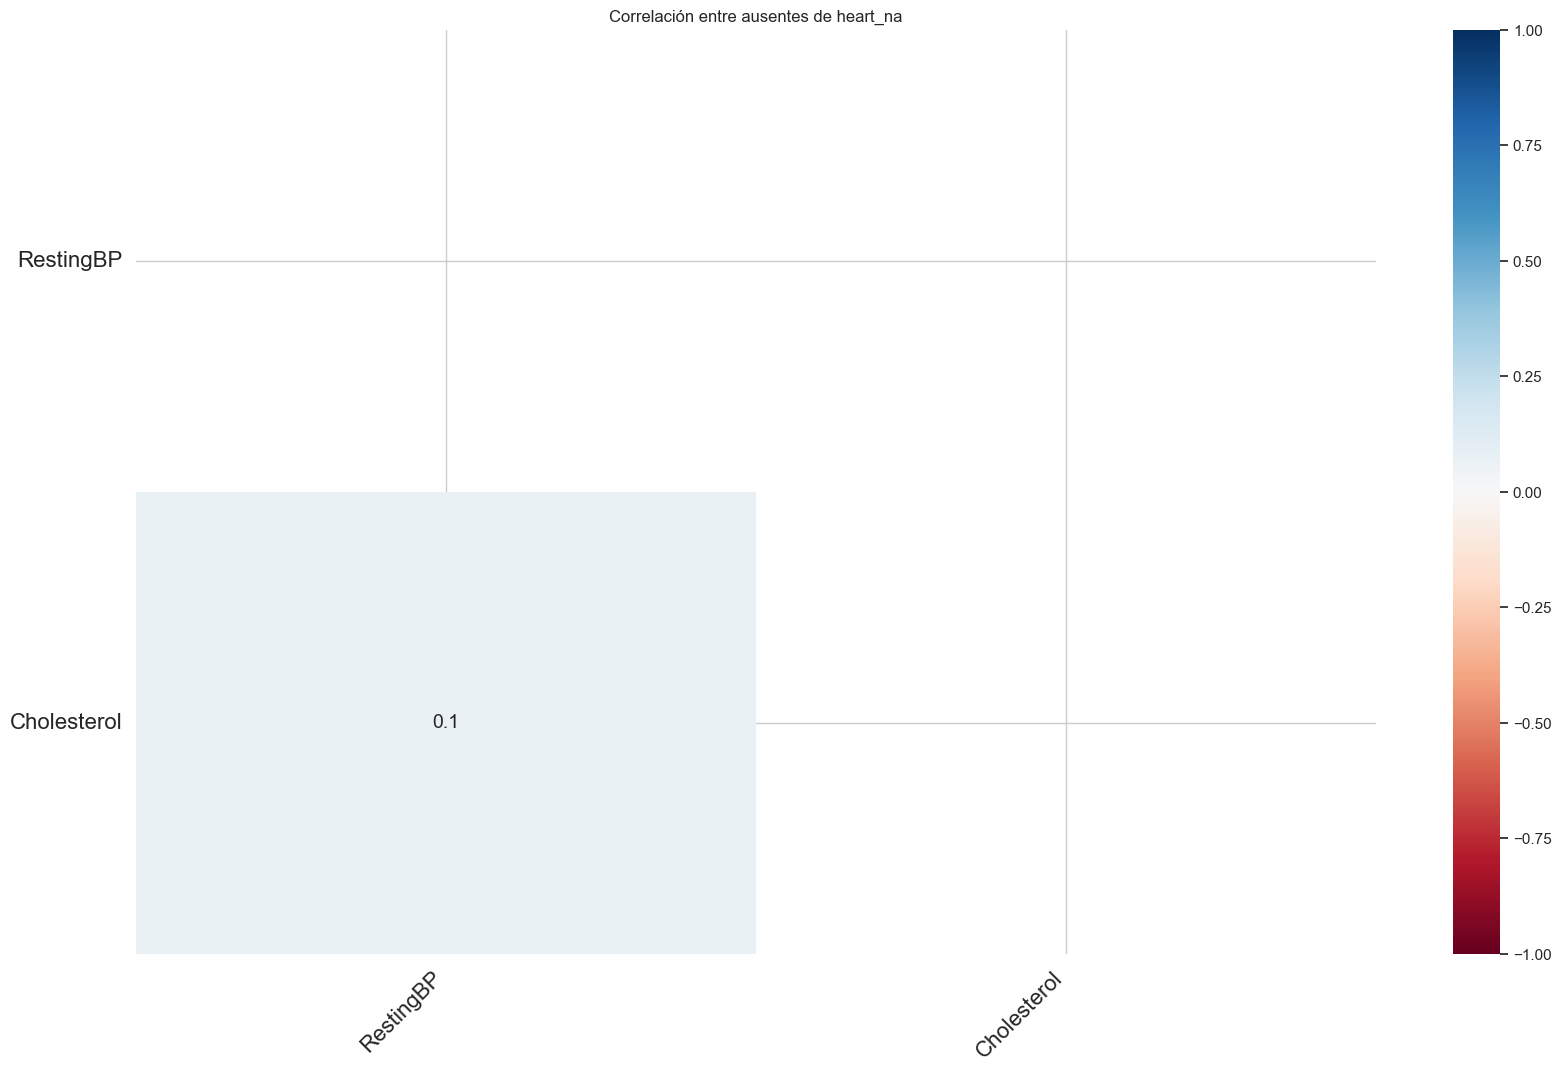

In [48]:
# TODO: msno.heatmap
msno.heatmap(heart_na)
plt.title('Correlación entre ausentes de heart_na')
plt.show()

**Preguntas:**

1. ¿Por qué `isnull()` no detecta estos ausentes? Además del 0, ¿qué otras formas de «disfrazar» un ausente conoces? ¿Qué parámetro de `pd.read_csv()` permite indicarlas al cargar el fichero?
2. ¿Por qué **no** has incluido `Oldpeak` ni `FastingBS` en `COLS_CERO_IMPOSIBLE`?
3. Hay una fila con dos ausentes. ¿Qué tiene de especial? ¿Es casualidad?
4. ¿Qué te dice `msno.matrix` sobre **dónde** están los ausentes? ¿Te parece útil el `msno.heatmap` con estos datos? ¿Por qué?

*Escribe aquí tus respuestas:*

1. Porque para pandas un 0 es un número normal y isnull() solo busca NaN o None. Otras formas son poner -1 o -999, escribir "?" o "N/A" o dejarlo en blanco. El parámetro es na_values
2. Porque en Oldpeak un 0 significa que el segmento ST no cambia con el esfuerzo, y en FastingBS el 0 es una de las dos categorías.
3. Es la fila 449, que tiene a 0 la presión y el colesterol a la vez. No creo que sea casualidad, está dentro del bloque donde falta casi todo el colesterol, así que será del mismo hospital.
4. Que los ausentes de colesterol están juntos en un bloque de filas, no repartidos. El heatmap no me parece muy útil porque solo hay dos columnas con ausentes y casi no se relacionan

## Ejercicio 1.2 — ¿Por qué falta el colesterol? Diagnóstico del mecanismo

Antes de decidir qué hacer con un ausente hay que averiguar **por qué falta** (MCAR, MAR o MNAR). La estrategia es la del Ejemplo 3 de la teoría: dividir a los pacientes en dos grupos, *con* y *sin* colesterol, y comparar el resto de variables.

**Parte A — Comparar los dos grupos.**
Añade a `heart_na` una columna booleana `chol_ausente`. Después:

1. Calcula el número de pacientes y el **porcentaje de enfermos** en cada grupo.
2. Calcula la media de `Age`, `RestingBP`, `MaxHR` y `Oldpeak` en cada grupo.
3. Con `pd.crosstab(..., normalize='index')`, compara la distribución (en %) de `Sex`, `ChestPainType`, `ExerciseAngina` y `ST_Slope` en los dos grupos.

In [49]:
# TODO: columna chol_ausente
heart_na['chol_ausente'] = heart_na['Cholesterol'].isnull()
grupos = heart_na.groupby('chol_ausente')

# TODO: n y % de enfermos por grupo
tabla_grupos = pd.DataFrame({
    'pacientes': grupos.size(),
    'porcentaje_enfermos': (grupos['HeartDisease'].mean() * 100).round(1)
})
print('Pacientes y % de enfermos por grupo:')
print(tabla_grupos)
print()

# TODO: medias de las numéricas por grupo
print('Medias por grupo:')
print(grupos[['Age', 'RestingBP', 'MaxHR', 'Oldpeak']].mean().round(2))
print()

# TODO: crosstabs normalizados por fila
for columna in ['Sex', 'ChestPainType', 'ExerciseAngina', 'ST_Slope']:
    print(f'{columna} (% por grupo):')
    print((pd.crosstab(heart_na['chol_ausente'], heart_na[columna], normalize='index') * 100).round(1))
    print()

Pacientes y % de enfermos por grupo:
              pacientes  porcentaje_enfermos
chol_ausente                                
False               746                 47.7
True                172                 88.4

Medias por grupo:
                Age  RestingBP   MaxHR  Oldpeak
chol_ausente                                   
False         52.88     133.02  140.23     0.90
True          56.24     130.44  121.99     0.83

Sex (% por grupo):
Sex              F     M
chol_ausente            
False         24.4  75.6
True           6.4  93.6

ChestPainType (% por grupo):
ChestPainType   ASY   ATA   NAP   TA
chol_ausente                        
False          49.6  22.3  22.7  5.5
True           73.3   4.1  19.8  2.9

ExerciseAngina (% por grupo):
ExerciseAngina     N     Y
chol_ausente              
False           61.5  38.5
True            51.2  48.8

ST_Slope (% por grupo):
ST_Slope      Down  Flat    Up
chol_ausente                  
False          5.8  47.5  46.8
True          11.

**Parte B — ¿Dónde están los ausentes?**
Recuerda que las filas del fichero están ordenadas por hospital de origen. Divide las filas en **10 tramos consecutivos** del mismo tamaño (pista: `pd.cut(heart_na.index, bins=10, labels=False)`) y dibuja en una figura de 1 × 2:

- a la izquierda, el **porcentaje de colesterol ausente** en cada tramo (barras);
- a la derecha, un boxplot de `MaxHR` según `chol_ausente`.

0     0.0
1     0.0
2     0.0
3    81.3
4    80.4
5    26.1
6     0.0
7     0.0
8     0.0
9     0.0
Name: chol_ausente, dtype: float64


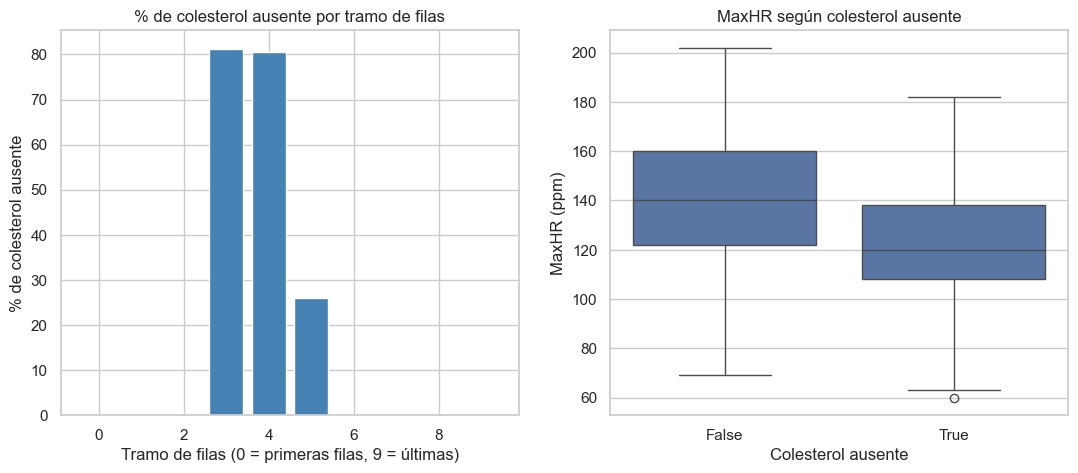

In [50]:
# TODO: % de ausentes por tramo de filas y boxplot de MaxHR
tramos = pd.cut(heart_na.index, bins=10, labels=False)
pct_por_tramo = heart_na.groupby(tramos)['chol_ausente'].mean() * 100
print(pct_por_tramo.round(1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.bar(pct_por_tramo.index, pct_por_tramo.values, color='steelblue')
ax1.set_title('% de colesterol ausente por tramo de filas')
ax1.set_xlabel('Tramo de filas (0 = primeras filas, 9 = últimas)')
ax1.set_ylabel('% de colesterol ausente')

sns.boxplot(data=heart_na, x='chol_ausente', y='MaxHR', ax=ax2)
ax2.set_title('MaxHR según colesterol ausente')
ax2.set_xlabel('Colesterol ausente')
ax2.set_ylabel('MaxHR (ppm)')

plt.show()

**Parte C — ¿Qué pasa si eliminamos las filas?**
La solución «rápida» sería `dropna()`. Construye una tabla que compare `heart_na` con `heart_na.dropna(subset=['Cholesterol'])` en: número de pacientes, % de enfermos, % de mujeres y % de pacientes asintomáticos (`ChestPainType == 'ASY'`).

In [51]:
# TODO: tabla comparativa antes / después de dropna
sin_ausentes = heart_na.dropna(subset=['Cholesterol'])

def resumen(df):
    return {
        'pacientes': len(df),
        '% enfermos': round(df['HeartDisease'].mean() * 100, 1),
        '% mujeres': round((df['Sex'] == 'F').mean() * 100, 1),
        '% asintomáticos (ASY)': round((df['ChestPainType'] == 'ASY').mean() * 100, 1)
    }

comparacion_dropna = pd.DataFrame({
    'antes (heart_na)': resumen(heart_na),
    'después (dropna)': resumen(sin_ausentes)
})
print(comparacion_dropna)

                       antes (heart_na)  después (dropna)
pacientes                         918.0             746.0
% enfermos                         55.3              47.7
% mujeres                          21.0              24.4
% asintomáticos (ASY)              54.0              49.6


**Preguntas:**

1. ¿Son los ausentes de `Cholesterol` **MCAR**? Justifícalo con al menos dos cifras de la Parte A.
2. Según la Parte B, ¿de qué depende realmente que falte el colesterol? ¿Lo clasificarías como MAR o como MNAR? Ten en cuenta que la variable de la que depende **no está** en el dataset.
3. ¿Qué le pasa al dataset si eliminas esas filas? ¿Qué pacientes salen perjudicados? ¿Qué consecuencias tendría para un modelo entrenado después?
4. Sin hacerlo todavía (el tratamiento es de la UD3), ¿qué alternativas a eliminar las filas se te ocurren?

*Escribe aquí tus respuestas:*

1. No, porque los dos grupos son muy distintos. Entre los que no tienen colesterol el 88,4% está enfermo y entre los que sí lo tienen el 47,7%. Y casi no hay mujeres sin colesterol, un 6,4% frente al 24,4%
2. Depende de la zona del fichero, es decir, del hospital. Los ausentes están casi todos en los tramos 3 y 4 y en el resto no hay. El hospital no está en el dataset, así que yo diría que es MNAR
3. Se queda en 746 pacientes y baja el porcentaje de enfermos del 55,3% al 47,7%. Salen perjudicados los enfermos de ese hospital y el modelo vería menos enfermos de los que hay.
4. Rellenarlo con la mediana, estimarlo con un modelo o no usar la variable. Lo mejor sería pedir el dato al hospital

## Ejercicio 1.3 — Laboratorio: los tres mecanismos de ausencia

En los datos reales nunca sabemos el valor que falta. Aquí haremos trampa: partimos de los pacientes **con** colesterol, así conocemos la media verdadera, y **provocamos** ausentes con cada mecanismo para ver qué efecto tiene.

**Parte A — Simulador.**
Crea `completo = heart[heart['Cholesterol'] > 0].copy()` y escribe una función `simular_ausentes(df, col, mecanismo, pct=0.25, seed=42)` que devuelva una **copia** de `df` con el `pct` de los valores de `col` cambiados a `NaN`. Las filas se eligen con `df.sample(n=k, weights=pesos, random_state=seed)`, con estos pesos:

| Mecanismo | Pesos | Qué simula |
|---|---|---|
| `'MCAR'` | todos 1 | Se pierden tubos de sangre al azar |
| `'MAR'` | 5 si `Age >= 60`, 1 si no | A los mayores se les hace menos la analítica |
| `'MNAR'` | 5 si `Cholesterol >= 260`, 1 si no | Los resultados altos se mandan a repetir y no llegan |

In [52]:
# TODO: completo y función simular_ausentes
completo = heart[heart['Cholesterol'] > 0].copy()

def simular_ausentes(df, col, mecanismo, pct=0.25, seed=42):
    copia = df.copy()
    k = round(len(df) * pct)

    if mecanismo == 'MCAR':
        pesos = pd.Series(1, index=df.index)
    elif mecanismo == 'MAR':
        pesos = pd.Series(np.where(df['Age'] >= 60, 5, 1), index=df.index)
    elif mecanismo == 'MNAR':
        pesos = pd.Series(np.where(df['Cholesterol'] >= 260, 5, 1), index=df.index)
    else:
        raise ValueError('Mecanismo no válido, usa MCAR, MAR o MNAR')

    elegidas = df.sample(n=k, weights=pesos, random_state=seed).index
    copia[col] = copia[col].astype(float)
    copia.loc[elegidas, col] = np.nan
    return copia

print('Pacientes con colesterol:', len(completo))
print('Ausentes que se provocan (25%):', round(len(completo) * 0.25))

Pacientes con colesterol: 746
Ausentes que se provocan (25%): 186


**Parte B — ¿Qué mecanismo sesga la media?**
Para cada mecanismo, construye una fila de una tabla con:

- `media_observada`: media de `Cholesterol` con los valores que quedan;
- `sesgo`: `media_observada` − media verdadera (la de `completo`);
- `edad_ausentes` y `edad_presentes`: media de `Age` en las filas con y sin ausente (la herramienta de diagnóstico del ejercicio 1.2).

Añade una primera fila `'verdadero'` con los valores de `completo`.

In [53]:
# TODO: tabla comparativa de los tres mecanismos
media_verdadera = completo['Cholesterol'].mean()

filas = {
    'verdadero': {
        'media_observada': media_verdadera,
        'sesgo': 0,
        'edad_ausentes': np.nan,
        'edad_presentes': completo['Age'].mean()
    }
}

simuladas = {}
for mecanismo in ['MCAR', 'MAR', 'MNAR']:
    simulado = simular_ausentes(completo, 'Cholesterol', mecanismo)
    simuladas[mecanismo] = simulado
    ausente = simulado['Cholesterol'].isnull()
    media_obs = simulado['Cholesterol'].mean()
    filas[mecanismo] = {
        'media_observada': media_obs,
        'sesgo': media_obs - media_verdadera,
        'edad_ausentes': simulado.loc[ausente, 'Age'].mean(),
        'edad_presentes': simulado.loc[~ausente, 'Age'].mean()
    }

tabla_mecanismos = pd.DataFrame(filas).T
print(tabla_mecanismos.round(2))
print()
print('Correlación entre Age y Cholesterol en completo:', round(completo['Age'].corr(completo['Cholesterol']), 3))

           media_observada  sesgo  edad_ausentes  edad_presentes
verdadero           244.64   0.00            NaN           52.88
MCAR                246.06   1.43          52.39           53.05
MAR                 242.98  -1.66          56.56           51.66
MNAR                232.48 -12.16          52.87           52.89

Correlación entre Age y Cholesterol en completo: 0.059


**Parte C — Distribuciones.**
Dibuja en un mismo gráfico la curva KDE de `Cholesterol` de `completo` y la de los valores observados con cada mecanismo. Usa una línea más gruesa para la distribución verdadera.

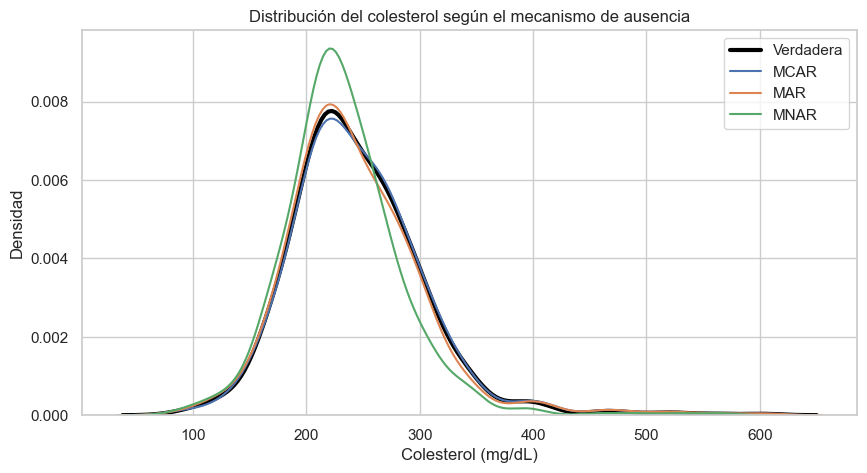

In [54]:
# TODO: KDE de la distribución verdadera y de las tres simuladas
plt.figure(figsize=(10, 5))
sns.kdeplot(completo['Cholesterol'], label='Verdadera', color='black', linewidth=3)
for mecanismo, simulado in simuladas.items():
    sns.kdeplot(simulado['Cholesterol'].dropna(), label=mecanismo)
plt.title('Distribución del colesterol según el mecanismo de ausencia')
plt.xlabel('Colesterol (mg/dL)')
plt.ylabel('Densidad')
plt.legend()
plt.show()

**Preguntas:**

1. ¿Qué mecanismo sesga claramente la media? ¿En qué sentido y por qué? En el caso MAR la media apenas cambia: ¿por qué? (Pista: calcula la correlación entre `Age` y `Cholesterol` en `completo`.)
2. En el caso MAR, ¿podrías haber descubierto el mecanismo con los datos observados? ¿Cómo?
3. En el caso MNAR, compara `edad_ausentes` y `edad_presentes`. ¿Te sirve esa comparación para detectarlo? ¿Por qué MNAR es el caso más peligroso?
4. Repite la Parte B con `seed=1`, `seed=2` y `seed=3`. ¿El sesgo de MCAR es exactamente 0? ¿Qué diferencia hay entre el «sesgo» de MCAR y el de MNAR?

*Escribe aquí tus respuestas:*

1. El MNAR, la media baja de 244,64 a 232,48 porque se pierden los colesteroles altos. En el MAR casi no cambia porque la edad y el colesterol casi no tienen relación, la correlación es 0,059
2. Si, mirando la edad de los que tienen el dato y los que no, como en el 1.2. En el MAR los ausentes tienen 56,56 años de media y los presentes 51,66
3. No sirve porque la edad es casi igual en los dos grupos. Es el más peligroso porque lo que hace que falte es el propio valor, no se ve con otras variables y la media sale mal sin ningún aviso
4. El sesgo de MCAR no es exactamente 0 pero es pequeño y cambia de signo según la semilla, así que es azar. En el MNAR sale siempre negativo, más o menos entre -10 y -12

## Ejercicio 1.4 — Tres detectores de atípicos

**Parte A — Funciones.**
Escribe tres funciones que reciban una `Series` y devuelvan una **máscara booleana** (misma longitud e índice que la serie; los `NaN` cuentan como `False`):

- `atipicos_iqr(serie, factor=1.5)`: fuera de `[Q1 − factor·IQR, Q3 + factor·IQR]`.
- `atipicos_z(serie, umbral=3)`: `|z| > umbral`, con `z = (x − media) / desviación típica`.
- `atipicos_zmod(serie, umbral=3.5)`: z-score modificado, `0,6745 · |x − mediana| / MAD > umbral`.

> Devolver una máscara (y no un número) permite después contar, filtrar filas o combinar métodos con `&` y `|`.

In [55]:
# TODO: atipicos_iqr, atipicos_z, atipicos_zmod
def atipicos_iqr(serie, factor=1.5):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return (serie < q1 - factor * iqr) | (serie > q3 + factor * iqr)

def atipicos_z(serie, umbral=3):
    z = (serie - serie.mean()) / serie.std()
    return z.abs() > umbral

def atipicos_zmod(serie, umbral=3.5):
    mediana = serie.median()
    mad = (serie - mediana).abs().median()
    zmod = 0.6745 * (serie - mediana).abs() / mad
    return zmod > umbral

# Pequeña prueba para ver que devuelven máscaras con el mismo índice
print(atipicos_iqr(heart_na['Cholesterol']).sum(), atipicos_z(heart_na['Cholesterol']).sum(), atipicos_zmod(heart_na['Cholesterol']).sum())

23 8 9


**Parte B — Comparación.**
Aplica los tres métodos a las variables de `NUMERICAS` de `heart_na` y muestra una tabla con una fila por variable, el número de atípicos de cada método y la asimetría (`skew()`).

In [56]:
# TODO: tabla de atípicos por método
filas = {}
for var in NUMERICAS:
    serie = heart_na[var]
    filas[var] = {
        'IQR': atipicos_iqr(serie).sum(),
        'z-score': atipicos_z(serie).sum(),
        'z modificado': atipicos_zmod(serie).sum(),
        'asimetría': serie.skew()
    }

tabla_atipicos = pd.DataFrame(filas).T
tabla_atipicos[['IQR', 'z-score', 'z modificado']] = tabla_atipicos[['IQR', 'z-score', 'z modificado']].astype(int)
print(tabla_atipicos.round(2))

             IQR  z-score  z modificado  asimetría
Age            0        0             0      -0.20
RestingBP     27        7             8       0.61
Cholesterol   23        8             9       1.24
MaxHR          2        1             0      -0.14
Oldpeak       16        7            16       1.02


**Parte C — Los límites, a la vista.**
Dibuja el histograma de `Cholesterol` de `heart_na` y marca con líneas verticales de un color distinto los límites de cada método (calcula los límites a mano a partir de las fórmulas).

IQR: 105.6 a 376.6
z-score: 67.2 a 422.1
z modificado: 60.6 a 413.4


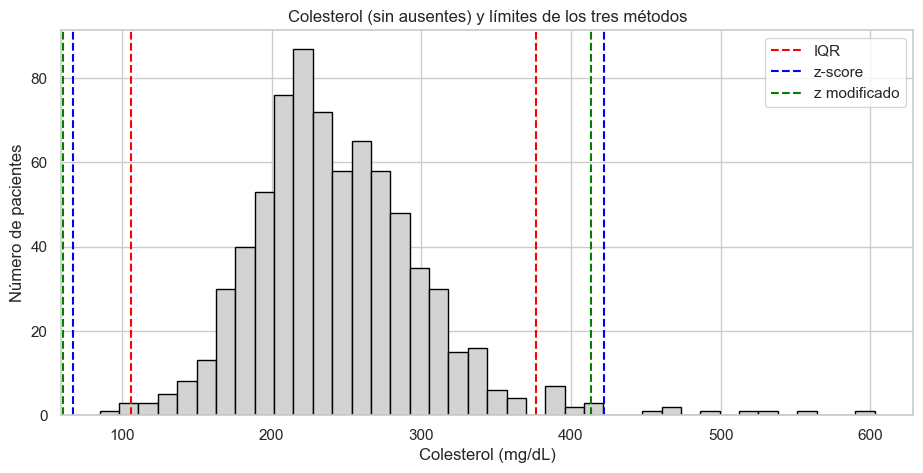

In [57]:
# TODO: histograma de Cholesterol con los límites de los tres métodos
col = heart_na['Cholesterol'].dropna()

# Límites IQR
q1, q3 = col.quantile(0.25), col.quantile(0.75)
iqr = q3 - q1
iqr_inf, iqr_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr

# Límites z-score
z_inf, z_sup = col.mean() - 3 * col.std(), col.mean() + 3 * col.std()

# Límites z modificado (se despeja x de la fórmula)
mediana = col.median()
mad = (col - mediana).abs().median()
zm_inf, zm_sup = mediana - 3.5 * mad / 0.6745, mediana + 3.5 * mad / 0.6745

print(f'IQR: {iqr_inf:.1f} a {iqr_sup:.1f}')
print(f'z-score: {z_inf:.1f} a {z_sup:.1f}')
print(f'z modificado: {zm_inf:.1f} a {zm_sup:.1f}')

plt.figure(figsize=(11, 5))
plt.hist(col, bins=40, color='lightgray', edgecolor='black')
plt.axvline(iqr_inf, color='red', linestyle='--', label='IQR')
plt.axvline(iqr_sup, color='red', linestyle='--')
plt.axvline(z_inf, color='blue', linestyle='--', label='z-score')
plt.axvline(z_sup, color='blue', linestyle='--')
plt.axvline(zm_inf, color='green', linestyle='--', label='z modificado')
plt.axvline(zm_sup, color='green', linestyle='--')
plt.title('Colesterol (sin ausentes) y límites de los tres métodos')
plt.xlabel('Colesterol (mg/dL)')
plt.ylabel('Número de pacientes')
plt.legend()
plt.show()

**Parte D — El efecto de los ceros.**
Repite el recuento de atípicos de `Cholesterol` con los tres métodos, pero sobre `heart` (con los ceros). Muestra los dos resultados juntos y, para cada método, cuántos de los atípicos detectados son ceros.

In [58]:
# TODO: atípicos de Cholesterol con y sin ceros
metodos = {'IQR': atipicos_iqr, 'z-score': atipicos_z, 'z modificado': atipicos_zmod}

filas = {}
for nombre, funcion in metodos.items():
    sin_ceros = funcion(heart_na['Cholesterol'])
    con_ceros = funcion(heart['Cholesterol'])
    filas[nombre] = {
        'atípicos sin ceros (heart_na)': sin_ceros.sum(),
        'atípicos con ceros (heart)': con_ceros.sum(),
        'de ellos son ceros': (con_ceros & (heart['Cholesterol'] == 0)).sum()
    }

print(pd.DataFrame(filas).T)

              atípicos sin ceros (heart_na)  atípicos con ceros (heart)  \
IQR                                      23                         183   
z-score                                   8                           3   
z modificado                              9                           7   

              de ellos son ceros  
IQR                          172  
z-score                        0  
z modificado                   0  


**Preguntas:**

1. ¿Qué método detecta más atípicos en `RestingBP` y en `Cholesterol`? ¿Y menos? Relaciónalo con la asimetría.
2. El z-score supone que los datos siguen una distribución aproximadamente normal. ¿En qué variables de `NUMERICAS` es razonable usarlo?
3. En la Parte D, ¿qué método «ve» los 172 ceros como atípicos y cuál no? Explica por qué el z-score se deja engañar (pista: ¿qué les pasa a la media y a la desviación típica cuando hay 172 ceros?).
4. Mirando la Parte C, ¿por qué el z-score modificado y el IQR dan límites parecidos y el z-score no?

*Escribe aquí tus respuestas:*

1. El IQR detecta más en las dos, 27 en RestingBP y 23 en Cholesterol, y el z-score menos, 7 y 8. Las dos tienen asimetría positiva.
2. En Age y MaxHR porque son casi simétricas. En Cholesterol y Oldpeak no tanto porque están sesgadas.
3. Solo el IQR ve los ceros, 172 de sus 183 atípicos. El z-score se deja engañar porque los ceros bajan la media y suben mucho la desviación, y el límite de abajo sale negativo. El z modificado tampoco los ve porque hay tantos ceros que el MAD sube y pasa lo mismo
4. En mi gráfico el z modificado y el z-score salen parecidos entre ellos y el IQR es el más estrecho. El z modificado y el IQR usan mediana y cuartiles, que cambian poco con los valores raros, y el z-score usa la media y la desviación

## Ejercicio 1.5 — ¿Error o valor real?

Un atípico **estadístico** no es necesariamente un **error**. Para separarlos necesitamos conocimiento del dominio. Estos son unos rangos de plausibilidad orientativos para adultos (no son criterios médicos):

In [59]:
# Rangos de plausibilidad orientativos: (mínimo, máximo)
REGLAS = {
    'Age':         (18, 100),    # años
    'RestingBP':   (60, 250),    # mm Hg
    'Cholesterol': (80, 650),    # mg/dL
    'MaxHR':       (50, 220),    # ppm
    'Oldpeak':     (-3, 7),      # mm
}

**Parte A — Reglas de dominio.**
Escribe una función `fuera_de_dominio(df, reglas)` que devuelva una tabla con una fila por variable y las columnas `minimo`, `maximo`, `n_por_debajo` y `n_por_encima`. Aplícala a `heart` y a `heart_na`.

In [60]:
# TODO: función fuera_de_dominio y aplicación a heart y heart_na
def fuera_de_dominio(df, reglas):
    filas = {}
    for var, (minimo, maximo) in reglas.items():
        filas[var] = {
            'minimo': minimo,
            'maximo': maximo,
            'n_por_debajo': (df[var] < minimo).sum(),
            'n_por_encima': (df[var] > maximo).sum()
        }
    return pd.DataFrame(filas).T

print('En heart:')
print(fuera_de_dominio(heart, REGLAS))
print()
print('En heart_na:')
print(fuera_de_dominio(heart_na, REGLAS))

En heart:
             minimo  maximo  n_por_debajo  n_por_encima
Age              18     100             0             0
RestingBP        60     250             1             0
Cholesterol      80     650           172             0
MaxHR            50     220             0             0
Oldpeak          -3       7             0             0

En heart_na:
             minimo  maximo  n_por_debajo  n_por_encima
Age              18     100             0             0
RestingBP        60     250             0             0
Cholesterol      80     650             0             0
MaxHR            50     220             0             0
Oldpeak          -3       7             0             0


**Parte B — Los casos extremos.**
Para cada variable de `NUMERICAS`, muestra los atípicos IQR de `heart_na` que **sí** están dentro del rango plausible: cuántos son y sus valores mínimo y máximo. Después muestra la fila completa del paciente con el colesterol más alto y la del paciente con la `MaxHR` más baja.

In [61]:
# TODO: atípicos IQR dentro del dominio
filas = {}
for var in NUMERICAS:
    minimo, maximo = REGLAS[var]
    serie = heart_na[var]
    dentro = serie[atipicos_iqr(serie) & serie.between(minimo, maximo)]
    filas[var] = {'n': len(dentro), 'valor_min': dentro.min(), 'valor_max': dentro.max()}
print(pd.DataFrame(filas).T)
print()

# TODO: filas de los pacientes más extremos
print('Paciente con el colesterol más alto:')
print(heart_na.loc[[heart_na['Cholesterol'].idxmax()]])
print()
print('Paciente con la MaxHR más baja:')
print(heart_na.loc[[heart_na['MaxHR'].idxmin()]])

                n  valor_min  valor_max
Age           0.0        NaN        NaN
RestingBP    27.0       80.0      200.0
Cholesterol  23.0       85.0      603.0
MaxHR         2.0       60.0       63.0
Oldpeak      16.0       -2.6        6.2

Paciente con el colesterol más alto:
     Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  \
149   54   M           ASY      130.0        603.0          1     Normal   

     MaxHR ExerciseAngina  Oldpeak ST_Slope  HeartDisease  chol_ausente  
149    125              Y      1.0     Flat             1         False  

Paciente con la MaxHR más baja:
     Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  \
390   51   M           ASY      140.0          NaN          0     Normal   

     MaxHR ExerciseAngina  Oldpeak ST_Slope  HeartDisease  chol_ausente  
390     60              N      0.0     Flat             1          True  


**Parte C — Atípicos multivariantes.**
Un valor puede ser normal en cada variable por separado y raro en **combinación**. Una regla clásica estima la frecuencia cardiaca máxima teórica de una persona como **220 − edad**. Calcula `pct_fc_teorica = MaxHR / (220 − Age) * 100` (qué porcentaje de su máximo teórico alcanzó cada paciente en la prueba) y:

1. Cuenta cuántos pacientes **superan el 100 %** de su máximo teórico y cuántos de ellos son atípicos IQR en `Age` o en `MaxHR`.
2. Cuenta cuántos **no llegan al 85 %** (en cardiología, no alcanzar el 85 % se llama *incompetencia cronotrópica*) y compara su porcentaje de enfermos con el del resto.
3. Dibuja `MaxHR` frente a `Age` coloreando en tres grupos (`< 85 %`, `85-100 %`, `> 100 %`) y añade la recta `220 − edad` como referencia.

Pacientes que superan el 100% de su máximo teórico: 87
De ellos son atípicos IQR en Age o MaxHR: 0

Pacientes que no llegan al 85%: 519
% de enfermos entre los que no llegan: 67.1
% de enfermos en el resto: 40.1


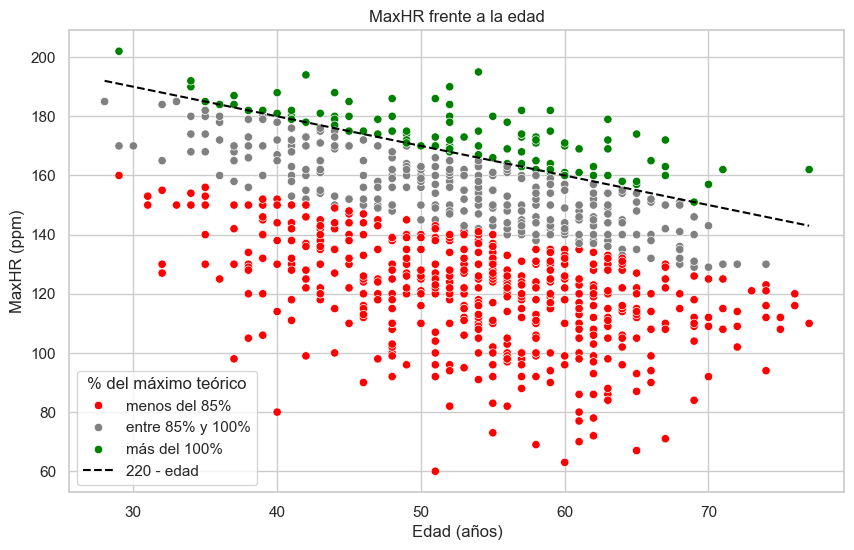

In [62]:
# TODO: pct_fc_teorica, recuentos y gráfico
heart_na['pct_fc_teorica'] = heart_na['MaxHR'] / (220 - heart_na['Age']) * 100

# 1. Los que superan el 100%
superan = heart_na['pct_fc_teorica'] > 100
atip_edad_o_fc = atipicos_iqr(heart_na['Age']) | atipicos_iqr(heart_na['MaxHR'])
print('Pacientes que superan el 100% de su máximo teórico:', superan.sum())
print('De ellos son atípicos IQR en Age o MaxHR:', (superan & atip_edad_o_fc).sum())
print()

# 2. Los que no llegan al 85%
no_llegan = heart_na['pct_fc_teorica'] < 85
print('Pacientes que no llegan al 85%:', no_llegan.sum())
print('% de enfermos entre los que no llegan:', round(heart_na.loc[no_llegan, 'HeartDisease'].mean() * 100, 1))
print('% de enfermos en el resto:', round(heart_na.loc[~no_llegan, 'HeartDisease'].mean() * 100, 1))

# 3. Gráfico
heart_na['grupo_fc'] = pd.cut(heart_na['pct_fc_teorica'], bins=[0, 85, 100, 1000],
                              labels=['menos del 85%', 'entre 85% y 100%', 'más del 100%'], right=False)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=heart_na, x='Age', y='MaxHR', hue='grupo_fc', palette=['red', 'gray', 'green'])
edades = np.linspace(heart_na['Age'].min(), heart_na['Age'].max(), 50)
plt.plot(edades, 220 - edades, color='black', linestyle='--', label='220 - edad')
plt.title('MaxHR frente a la edad')
plt.xlabel('Edad (años)')
plt.ylabel('MaxHR (ppm)')
plt.legend(title='% del máximo teórico')
plt.show()

**Parte D — Informe de calidad.**
Escribe una función `informe_calidad(df, reglas)` que devuelva un DataFrame con una fila por columna **numérica** y las columnas `dtype`, `n_ausentes`, `pct_ausentes`, `n_atipicos_iqr`, `pct_atipicos_iqr` y `n_fuera_dominio` (esta última solo para las columnas que estén en `reglas`; en las demás, 0). Aplícala a `heart_raw` y a `heart_na` y muestra los dos resultados.

> La usarás otra vez en el ejercicio 2.6.

In [63]:
# TODO: función informe_calidad
def informe_calidad(df, reglas):
    numericas = df.select_dtypes(include='number').columns
    n = len(df)
    filas = {}
    for var in numericas:
        serie = df[var]
        if var in reglas:
            minimo, maximo = reglas[var]
            fuera = ((serie < minimo) | (serie > maximo)).sum()
        else:
            fuera = 0
        filas[var] = {
            'dtype': str(serie.dtype),
            'n_ausentes': serie.isnull().sum(),
            'pct_ausentes': round(serie.isnull().sum() / n * 100, 2),
            'n_atipicos_iqr': atipicos_iqr(serie).sum(),
            'pct_atipicos_iqr': round(atipicos_iqr(serie).sum() / n * 100, 2),
            'n_fuera_dominio': fuera
        }
    return pd.DataFrame(filas).T

print('Informe de heart_raw:')
display(informe_calidad(heart_raw, REGLAS))
print('Informe de heart_na:')
display(informe_calidad(heart_na.drop(columns=['pct_fc_teorica']), REGLAS))

Informe de heart_raw:


,dtype,n_ausentes,pct_ausentes,n_atipicos_iqr,pct_atipicos_iqr,n_fuera_dominio
Age,int64,0,0.0,0,0.0,0
RestingBP,int64,0,0.0,28,3.05,1
Cholesterol,int64,0,0.0,183,19.93,172
FastingBS,int64,0,0.0,214,23.31,0
MaxHR,int64,0,0.0,2,0.22,0
Oldpeak,float64,0,0.0,16,1.74,0
HeartDisease,int64,0,0.0,0,0.0,0


Informe de heart_na:


,dtype,n_ausentes,pct_ausentes,n_atipicos_iqr,pct_atipicos_iqr,n_fuera_dominio
Age,int64,0,0.0,0,0.0,0
RestingBP,float64,1,0.11,27,2.94,0
Cholesterol,float64,172,18.74,23,2.51,0
FastingBS,int64,0,0.0,214,23.31,0
MaxHR,int64,0,0.0,2,0.22,0
Oldpeak,float64,0,0.0,16,1.74,0
HeartDisease,int64,0,0.0,0,0.0,0


**Preguntas:**

1. Una vez convertidos los ceros en `NaN`, ¿queda algún valor fuera del rango plausible? ¿Qué conclusión sacas sobre los atípicos de este dataset?
2. Busca qué significa un `Oldpeak` negativo y uno de 6 mm. ¿Los eliminarías?
3. Los pacientes que superan el 100 % de su frecuencia máxima teórica, ¿son errores? ¿Por qué no aparecen como atípicos si miras la edad y la frecuencia por separado? (Pista: busca qué precisión tiene la fórmula 220 − edad.)
4. ¿Qué te dice la Parte C.2 sobre la utilidad de crear variables **derivadas** durante el AED?
5. Completa la tabla con al menos cuatro casos que hayas encontrado en este ejercicio y en el 1.4:

| Variable | Valor(es) | ¿Atípico estadístico? | ¿Fuera de dominio? | Decisión: error / extremo real / dudoso | Justificación |
|---|---|---|---|---|---|
| Cholesterol | 0 | Sí | Sí | Error | Un colesterol de 0 no existe, es un ausente |
| RestingBP | 0 | Sí | Sí | Error | Una presión de 0 es imposible en una persona viva |
| Cholesterol | 603 | Sí | No | Extremo real | Es muy alto pero posible |
| Oldpeak | 6,2 | Sí | No | Extremo real | Raro pero posible |
| Oldpeak | Negativos | Sí | No | Extremo real | Es elevación del segmento ST |
| MaxHR | 60 | Sí | No | Dudoso | Muy bajo pero puede ser real |

*Escribe aquí tus respuestas:*

1. No queda ninguno fuera de rango. Los atípicos que quedan son raros pero posibles, los errores eran los ceros
2. Un Oldpeak negativo es que el segmento ST sube con el esfuerzo, así que tiene sentido. Uno de 6 mm es muy grande pero solo lo tiene una paciente enferma. No los eliminaría.
3. No tienen por qué ser errores, la fórmula 220 menos la edad es solo una estimación y hay gente que la supera, son 87 pacientes. No salen como atípicos porque la edad y la frecuencia por separado son normales, lo raro es la combinación.
4. Que crear variables nuevas puede enseñar cosas que no se ven mirando cada variable sola. Los que no llegan al 85% tienen un 67,1% de enfermos frente al 40,1% del resto.
5. La tabla está completada arriba

---
# Sesión 2 — Datos incorrectos, codificación y cobertura

## El fichero `heart_sucio.csv`

Imagina que los datos no te llegan ya preparados de Kaggle, sino que **tres centros** (*Hospital Norte*, *Clínica Sur* y *Hospital Este*) te envían una exportación de sus registros. Cada centro usa su propio programa, su propio Excel y sus propias costumbres. El resultado es `datos/heart_sucio.csv`, que viene con el repositorio.

> Es un fichero **simulado para practicar**: contiene los mismos 918 pacientes de `heart.csv`, pero con los errores típicos de una exportación real introducidos a propósito. Los nombres de los centros son inventados.

Además de las 12 variables que ya conoces, tiene cuatro columnas nuevas:

| Variable | Descripción |
|---|---|
| `id_paciente` | Identificador del paciente (`P0001`, `P0002`…) |
| `centro` | Centro que envió el registro |
| `fecha_visita` | Fecha en la que se hicieron las pruebas |
| `observaciones` | Comentario libre del personal sanitario |

El fichero se exportó el **30 de junio de 2026**.

In [64]:
RUTA_SUCIO = DATOS / 'heart_sucio.csv'
FECHA_EXPORTACION = pd.Timestamp('2026-06-30')
print('¿Existe el fichero?', RUTA_SUCIO.exists())

¿Existe el fichero? True


## Ejercicio 2.1 — Un fichero que no quiere cargarse

**Parte A — Encoding y separador.**

1. Intenta cargar el fichero con `pd.read_csv(RUTA_SUCIO)` dentro de un `try/except` y muestra el tipo de error y el mensaje.
2. Lee los bytes del fichero (`RUTA_SUCIO.read_bytes()`) e intenta decodificarlos con `'utf-8'`, `'latin-1'` y `'cp1252'`. ¿Con cuáles funciona?
3. Muestra las tres primeras líneas del fichero ya decodificado. ¿Qué separador usa?

> Opcional: la librería `charset_normalizer` (viene instalada con `requests`) puede adivinar el encoding: `from charset_normalizer import from_path; from_path(RUTA_SUCIO).best().encoding`.

In [65]:
# TODO: intento de carga con try/except
try:
    pd.read_csv(RUTA_SUCIO)
except Exception as e:
    print('Tipo de error:', type(e).__name__)
    print('Mensaje:', e)
print()

# TODO: probar los tres encodings
contenido = RUTA_SUCIO.read_bytes()
for encoding in ['utf-8', 'latin-1', 'cp1252']:
    try:
        contenido.decode(encoding)
        print(f'{encoding}: funciona')
    except UnicodeDecodeError as e:
        print(f'{encoding}: falla ({e.reason})')
print()

# TODO: primeras líneas
texto = contenido.decode('latin-1')
for linea in texto.splitlines()[:3]:
    print(linea)

Tipo de error: UnicodeDecodeError
Mensaje: 'utf-8' codec can't decode byte 0xed in position 410: invalid continuation byte

utf-8: falla (invalid continuation byte)
latin-1: funciona
cp1252: funciona

id_paciente;centro;fecha_visita;Age;Sex;ChestPainType;RestingBP;Cholesterol;FastingBS;RestingECG;MaxHR;ExerciseAngina;Oldpeak;ST_Slope;HeartDisease;observaciones
P0173;Hospital Norte;2025-10-31;53;M;ATA;140;320;0;Normal;162;N;0.0;Up;0;
P0160;Hospital Norte;2024-08-06;54;M;ATA;160;195;0;ST;130;N;1.0;Up;0;


**Parte B — Carga «en crudo».**
Para ver los datos **exactamente** como vienen, sin que pandas interprete nada, cárgalos así y guárdalos en `sucio_raw` (no la modifiques) y una copia de trabajo en `sucio`:

```python
pd.read_csv(RUTA_SUCIO, sep=..., encoding=..., dtype=str, keep_default_na=False)
```

Muestra las dimensiones, 10 filas al azar (`random_state=0`) e `info()`.

In [66]:
# TODO: sucio_raw y sucio
sucio_raw = pd.read_csv(RUTA_SUCIO, sep=';', encoding='latin-1', dtype=str, keep_default_na=False)
sucio = sucio_raw.copy()

print('Dimensiones:', sucio.shape)
print()
print('10 filas al azar:')
display(sucio.sample(n=10, random_state=0))
print()
sucio.info()

Dimensiones: (936, 16)

10 filas al azar:


,id_paciente,centro,fecha_visita,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,observaciones
825,P0420,Clínica Sur,23/09/2025,55,Hombre,ASY,142,228,No,ST,149,Sí,"2,5",Up,1,
236,P0544,Hospital Este,03-11-2025,70,M,ASY,170,192,NO,ST,129,Y,3,Down,1,
803,P0172,Hospital Norte,2025-03-12,40,M,NAP,140,235,0,Normal,188,N,0.0,Up,0,
767,P0298,Clínica Sur,19/03/2024,57,Hombre,ASY,110,?,Sí,ST,131,Sí,"1,4",Up,1,
266,P0673,Hospital Este,31-08-2025,60,F,NAP,120,178,sí,Normal,96,N,0,Up,0,
14,P0430,Clínica Sur,22/01/2024,63,Hombre,,,,,,,,,,1,
521,P0042,Hospital Norte,2025-01-15,54,F,NAP,130,294,0,ST,100,Y,0.0,Flat,1,
783,P0049,Hospital Norte,2024-12-03,36,M,NAP,112,340,0,Normal,184,N,1.0,Flat,0,Revisión en 6 meses
55,P0326,Clínica Sur,26/06/2024,42,Hombre,ASY,105,0,Sí,Normal,128,Sí,"-1,5",Down,1,
358,P0550,Hospital Este,09-11-2024,68,M,TA,139,181,si,ST,135,N,"0,2",Up,0,



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 936 entries, 0 to 935
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id_paciente     936 non-null    object
 1   centro          936 non-null    object
 2   fecha_visita    936 non-null    object
 3   Age             936 non-null    object
 4   Sex             936 non-null    object
 5   ChestPainType   936 non-null    object
 6   RestingBP       936 non-null    object
 7   Cholesterol     936 non-null    object
 8   FastingBS       936 non-null    object
 9   RestingECG      936 non-null    object
 10  MaxHR           936 non-null    object
 11  ExerciseAngina  936 non-null    object
 12  Oldpeak         936 non-null    object
 13  ST_Slope        936 non-null    object
 14  HeartDisease    936 non-null    object
 15  observaciones   936 non-null    object
dtypes: object(16)
memory usage: 117.1+ KB


**Parte C — ¿Qué no es un número?**
Escribe una función `no_numericos(serie)` que devuelva un `value_counts()` de los valores **no vacíos** de la serie que `pd.to_numeric(..., errors='coerce')` no consigue convertir. Aplícala a las columnas que deberían ser numéricas (`Age`, `RestingBP`, `Cholesterol`, `FastingBS`, `MaxHR`, `Oldpeak`, `HeartDisease`) y resume el resultado en una tabla con el número de valores no convertibles y hasta 5 ejemplos distintos.

In [67]:
COLS_NUM_SUCIO = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease']

# TODO: función no_numericos y tabla resumen
def no_numericos(serie):
    vacios = serie == ''
    convertido = pd.to_numeric(serie, errors='coerce')
    return serie[~vacios & convertido.isna()].value_counts()

resumen = {}
for col in COLS_NUM_SUCIO:
    no_num = no_numericos(sucio[col])
    resumen[col] = {
        'no_convertibles': no_num.sum(),
        'ejemplos': list(no_num.index[:5])
    }

resumen_no_numericos = pd.DataFrame(resumen).T
pd.set_option('display.max_colwidth', 80)
display(resumen_no_numericos)

,no_convertibles,ejemplos
Age,8,"[N/A, 58 años, 42 años, 55 años, 56 años]"
RestingBP,1,[13O]
Cholesterol,66,"[?, 6,7, 5,1, 7,3, 7,1]"
FastingBS,630,"[NO, no, No, Sí, SI]"
MaxHR,19,"[165 lpm, 160 lpm, 155 lpm, 112 lpm, 157 lpm]"
Oldpeak,332,"[1,5, 1,2, 0,2, 1,4, 1,8]"
HeartDisease,0,[]


**Preguntas:**

1. ¿Qué encoding tiene el fichero? ¿Por qué falla `utf-8` y, sin embargo, `latin-1` «funciona» siempre? (Pista: ¿puede fallar alguna vez `latin-1` al decodificar?) ¿Qué programa suele generar ficheros así?
2. ¿Por qué cargamos con `dtype=str` y `keep_default_na=False`? ¿Qué habría hecho pandas con los valores `'N/A'` y `''` si no hubiéramos puesto `keep_default_na=False`?
3. Según la Parte C, ¿qué tipos de problema hay en las columnas numéricas? Agrúpalos (símbolos o unidades, separador decimal, ausentes codificados, booleanos en texto, errores de tecleo…).
4. ¿Qué volumetría tiene el fichero? ¿Cuadra con los 918 pacientes de `heart.csv`? ¿Qué te hace sospechar?

*Escribe aquí tus respuestas:*

1. Está en latin-1, que es lo que suele sacar Excel en español. Falla utf-8 porque letras como la í no las reconoce. Latin-1 funciona siempre porque acepta cualquier byte, aunque a veces lea mal los caracteres. El separador es el punto y coma.
2. Con dtype=str pandas no convierte nada y veo los datos tal como vienen. Con keep_default_na=False no cambia los N/A y los vacíos por NaN, así sé qué había escrito cada centro.
3. Unidades junto al número, como años y lpm. Coma decimal en Oldpeak y Cholesterol. Ausentes escritos como ? y N/A. Booleanos escritos en texto en FastingBS. Y un error de tecleo, 13O con la letra O
4. Tiene 936 filas y 16 columnas y no cuadra con los 918 pacientes, sobran 18. que hay duplicados

## Ejercicio 2.2 — Duplicados: exactos, reenviados y contradictorios

**Parte A — Duplicados exactos.**
Cuenta las filas que son duplicado **exacto** de otra y muéstralas junto a su original (`keep=False`), ordenadas por `id_paciente`.

In [68]:
# TODO: duplicados exactos
print('Filas que son duplicado exacto de otra:', sucio.duplicated().sum())
exactos = sucio[sucio.duplicated(keep=False)].sort_values('id_paciente')
display(exactos)

Filas que son duplicado exacto de otra: 10


,id_paciente,centro,fecha_visita,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,observaciones
696,P0002,Hospital Norte,2024-05-14,49,F,nap,160,180,0,Normal,156,N,1.0,Flat,1,
473,P0002,Hospital Norte,2024-05-14,49,F,nap,160,180,0,Normal,156,N,1.0,Flat,1,
569,P0012,H. Norte,2025-07-22,58,M,ATA,136,164,0,ST,99,Y,2.0,Flat,1,
355,P0012,H. Norte,2025-07-22,58,M,ATA,136,164,0,ST,99,Y,2.0,Flat,1,
926,P0029,Hospital Norte,2024-03-31,53,F,ATA,113,468,0,Normal,127,N,0.0,Up,0,Revisión en 6 meses
735,P0029,Hospital Norte,2024-03-31,53,F,ATA,113,468,0,Normal,127,N,0.0,Up,0,Revisión en 6 meses
767,P0298,Clínica Sur,19/03/2024,57,Hombre,ASY,110,?,Sí,ST,131,Sí,"1,4",Up,1,
540,P0298,Clínica Sur,19/03/2024,57,Hombre,ASY,110,?,Sí,ST,131,Sí,"1,4",Up,1,
574,P0356,Clínica Sur,06/05/2024,67,Hombre,TA,145,?,No,LVH,125,No,0,Flat,1,
172,P0356,Clínica Sur,06/05/2024,67,Hombre,TA,145,?,No,LVH,125,No,0,Flat,1,


**Parte B — Duplicados por identificador.**

1. Quita los duplicados exactos y guarda el resultado en `sucio_sin_exactos`.
2. Busca los `id_paciente` que siguen apareciendo más de una vez.
3. Para cada uno de esos identificadores, averigua **qué columnas** tienen valores distintos entre sus filas. Muestra una tabla `id_paciente → columnas que difieren`.

In [69]:
# TODO: sucio_sin_exactos, ids repetidos y columnas que difieren
sucio_sin_exactos = sucio.drop_duplicates().copy()
print('Filas tras quitar los exactos:', len(sucio_sin_exactos))

conteo_ids = sucio_sin_exactos['id_paciente'].value_counts()
ids_repetidos = conteo_ids[conteo_ids > 1].index.tolist()
print('Identificadores que siguen repetidos:', len(ids_repetidos))
print()

columnas_difieren = {}
for id_pac in ids_repetidos:
    grupo = sucio_sin_exactos[sucio_sin_exactos['id_paciente'] == id_pac]
    columnas_difieren[id_pac] = [c for c in grupo.columns if grupo[c].nunique() > 1]

tabla_difieren = pd.DataFrame({'columnas que difieren': pd.Series(columnas_difieren)})
display(tabla_difieren)

Filas tras quitar los exactos: 926
Identificadores que siguen repetidos: 8



,columnas que difieren
P0546,[MaxHR]
P0013,"[centro, fecha_visita]"
P0259,"[centro, fecha_visita]"
P0883,[MaxHR]
P0285,"[centro, fecha_visita]"
P0048,"[centro, fecha_visita]"
P0108,"[centro, fecha_visita]"
P0121,"[centro, fecha_visita]"


**Parte C — Decisión.**
Hay dos tipos de duplicado por identificador: los que solo cambian de **formato** (el centro reenvió el registro) y los que tienen un **dato clínico distinto**.

1. Crea en `sucio_sin_exactos` una columna booleana `revisar` que valga `True` en las filas de los identificadores con algún dato clínico distinto.
2. Crea `sucio_dedup` quedándote con la **primera** aparición de cada `id_paciente`.
3. Comprueba que `sucio_dedup` tiene una fila por paciente.

In [70]:
# TODO: columna revisar, sucio_dedup y comprobación
# Columnas clínicas: si difiere alguna de estas, el dato es distinto de verdad
COLS_CLINICAS = ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
                 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

ids_revisar = [i for i, columnas in columnas_difieren.items()
               if any(c in COLS_CLINICAS for c in columnas)]
print('Identificadores con un dato clínico distinto:', ids_revisar)

sucio_sin_exactos['revisar'] = sucio_sin_exactos['id_paciente'].isin(ids_revisar)

sucio_dedup = sucio_sin_exactos.drop_duplicates(subset='id_paciente', keep='first').copy()

print('Filas de sucio_dedup:', len(sucio_dedup))
print('Una fila por paciente:', sucio_dedup['id_paciente'].is_unique)
print('Filas marcadas para revisar:', sucio_dedup['revisar'].sum())

Identificadores con un dato clínico distinto: ['P0546', 'P0883']
Filas de sucio_dedup: 918
Una fila por paciente: True
Filas marcadas para revisar: 2


**Preguntas:**

1. ¿Por qué `duplicated()` no detecta los registros reenviados? ¿Qué habría pasado si hubieras normalizado antes el texto y las fechas?
2. En los duplicados contradictorios, ¿cuál de los dos valores es el correcto? ¿Puedes saberlo con los datos que tienes? ¿Qué harías en un proyecto real?
3. Quedarse con la «primera aparición» depende del orden de las filas. ¿Qué criterio sería mejor si el fichero tuviera, por ejemplo, una fecha de modificación del registro?
4. En el Bloque 2 no podías saber si un paciente aparecía dos veces. ¿Qué ha cambiado aquí?

*Escribe aquí tus respuestas:*

1. Porque duplicated() solo detecta filas idénticas y los reenviados cambian el formato de la fecha y las mayúsculas del centro. Si hubiera normalizado antes, saldrían como duplicados exactos
2. No puedo saber cual es el correcto con los datos que tengo, son P0546 y P0883 con MaxHR distinto. En un proyecto real le preguntaría al centro y mientras tanto los dejaría marcados
3. Me quedaría con el registro más reciente
4. Que ahora hay una columna id_paciente, y con ella se encuentran los repetidos aunque cambie algún dato.

## Ejercicio 2.3 — Texto y categorías: normalizar y validar

A partir de aquí trabaja sobre `sucio_dedup`. Crea `limpio = sucio_dedup.copy()` y ve corrigiendo sobre `limpio`.

**Parte A — Inventario.**
Muestra el `value_counts()` de `centro`, `Sex`, `ChestPainType`, `RestingECG`, `ST_Slope`, `FastingBS` y `ExerciseAngina`.

In [71]:
COLS_TEXTO = ['centro', 'Sex', 'ChestPainType', 'RestingECG', 'ST_Slope', 'FastingBS', 'ExerciseAngina']

# TODO: limpio = ...  y value_counts de cada columna
limpio = sucio_dedup.copy()

for col in COLS_TEXTO:
    print(f'--- {col} ---')
    print(limpio[col].value_counts())
    print()

--- centro ---
centro
Hospital Este      327
Hospital Norte     252
Clínica Sur        215
Hosp. Este          15
Hospital Este       14
Hospital  Este      13
hospital norte      12
hospital este       12
Hospital Norte      10
H. Norte            10
HOSPITAL NORTE       9
CLINICA SUR          9
Clinica Sur          7
clínica sur          7
Clínica  Sur         6
Name: count, dtype: int64

--- Sex ---
Sex
M         457
Hombre    232
F         171
M          15
Mujer      12
 M         11
m           6
F           4
male        4
female      2
 F          2
f           2
Name: count, dtype: int64

--- ChestPainType ---
ChestPainType
ASY     472
NAP     188
ATA     164
TA       44
         20
ASY       7
asy       7
 ASY      5
 NAP      4
 TA       2
nap       2
 ATA      1
ATA       1
ata       1
Name: count, dtype: int64

--- RestingECG ---
RestingECG
Normal     528
LVH        183
ST         170
 Normal      8
             8
normal       5
NORMAL       4
 ST          4
Normal       2

**Parte B — Normalización.**

1. Escribe una función `normalizar_texto(serie)` que quite los espacios al principio y al final, convierta los espacios múltiples en uno solo, pase todo a minúsculas y convierta las cadenas vacías en `NaN`.
2. Aplícala a las columnas de `COLS_TEXTO` y vuelve a mirar sus valores distintos.
3. Escribe un diccionario de mapeo por columna que lleve cada variante a su valor **canónico** y aplícalo:
   - `centro` → `'Hospital Norte'`, `'Clínica Sur'`, `'Hospital Este'`
   - `Sex` → `'M'`, `'F'` · `ChestPainType` → `'TA'`, `'ATA'`, `'NAP'`, `'ASY'` · `RestingECG` → `'Normal'`, `'ST'`, `'LVH'` · `ST_Slope` → `'Up'`, `'Flat'`, `'Down'`
   - `ExerciseAngina` → `'Y'`, `'N'` · `FastingBS` → `0`, `1`

In [72]:
# TODO: función normalizar_texto
def normalizar_texto(serie):
    serie = serie.str.strip()
    serie = serie.str.replace(r'\s+', ' ', regex=True)
    serie = serie.str.lower()
    return serie.replace('', np.nan)

for col in COLS_TEXTO:
    limpio[col] = normalizar_texto(limpio[col])
    print(f'{col}:', sorted(limpio[col].dropna().unique()))

# TODO: MAPEOS = {'centro': {...}, 'Sex': {...}, ...} y aplicación
MAPEOS = {
    'centro': {'hospital norte': 'Hospital Norte', 'h. norte': 'Hospital Norte',
               'clínica sur': 'Clínica Sur', 'clinica sur': 'Clínica Sur',
               'hospital este': 'Hospital Este', 'hosp. este': 'Hospital Este'},
    'Sex': {'m': 'M', 'hombre': 'M', 'male': 'M', 'f': 'F', 'mujer': 'F', 'female': 'F'},
    'ChestPainType': {'ta': 'TA', 'ata': 'ATA', 'nap': 'NAP', 'asy': 'ASY'},
    'RestingECG': {'normal': 'Normal', 'st': 'ST', 'lvh': 'LVH'},
    'ST_Slope': {'up': 'Up', 'flat': 'Flat', 'down': 'Down'},
    'ExerciseAngina': {'y': 'Y', 'yes': 'Y', 'sí': 'Y', 'si': 'Y', 'n': 'N', 'no': 'N'},
    'FastingBS': {'0': 0, '1': 1, 'no': 0, 'sí': 1, 'si': 1},
}

print()
for col, mapeo in MAPEOS.items():
    nuevo = limpio[col].map(mapeo)
    sin_mapear = (limpio[col].notna() & nuevo.isna()).sum()
    print(f'{col}: valores sin mapear = {sin_mapear}')
    limpio[col] = nuevo

centro: ['clinica sur', 'clínica sur', 'h. norte', 'hosp. este', 'hospital este', 'hospital norte']
Sex: ['f', 'female', 'hombre', 'm', 'male', 'mujer']
ChestPainType: ['asy', 'ata', 'nap', 'ta']
RestingECG: ['lvh', 'normal', 'st']
ST_Slope: ['down', 'flat', 'up']
FastingBS: ['0', '1', 'no', 'si', 'sí']
ExerciseAngina: ['n', 'no', 'sí', 'y', 'yes']

centro: valores sin mapear = 0
Sex: valores sin mapear = 0
ChestPainType: valores sin mapear = 0
RestingECG: valores sin mapear = 0
ST_Slope: valores sin mapear = 0
ExerciseAngina: valores sin mapear = 0
FastingBS: valores sin mapear = 0


**Parte C — Validación contra el dominio.**
Escribe una función `validar_categorias(df, dominios)` que, para cada columna de `dominios` (un diccionario `columna → lista de valores permitidos`), devuelva el número de valores **no nulos** que no están en la lista y algunos ejemplos. Aplícala a `limpio`: todas las columnas deben dar 0. Si alguna no da 0, vuelve a la Parte B.

In [73]:
# TODO: DOMINIOS y validar_categorias
DOMINIOS = {
    'centro': ['Hospital Norte', 'Clínica Sur', 'Hospital Este'],
    'Sex': ['M', 'F'],
    'ChestPainType': ['TA', 'ATA', 'NAP', 'ASY'],
    'RestingECG': ['Normal', 'ST', 'LVH'],
    'ST_Slope': ['Up', 'Flat', 'Down'],
    'ExerciseAngina': ['Y', 'N'],
    'FastingBS': [0, 1],
}

def validar_categorias(df, dominios):
    filas = {}
    for col, permitidos in dominios.items():
        no_nulos = df[col].dropna()
        invalidos = no_nulos[~no_nulos.isin(permitidos)]
        filas[col] = {'n_invalidos': len(invalidos), 'ejemplos': list(invalidos.unique()[:5])}
    return pd.DataFrame(filas).T

validar_categorias(limpio, DOMINIOS)

,n_invalidos,ejemplos
centro,0,[]
Sex,0,[]
ChestPainType,0,[]
RestingECG,0,[]
ST_Slope,0,[]
ExerciseAngina,0,[]
FastingBS,0,[]


**Parte D — Tipos.**
Convierte `centro`, `Sex`, `ChestPainType`, `RestingECG` y `ExerciseAngina` a `category`, `ST_Slope` a una categórica **ordenada** (usa el orden que decidiste en el Bloque 2) y `FastingBS` a `Int64` (entero que admite ausentes). Muestra `limpio.dtypes`.

In [74]:
# TODO: conversión de tipos
columnas_category = ['centro', 'Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina']
limpio[columnas_category] = limpio[columnas_category].astype('category')

limpio['ST_Slope'] = limpio['ST_Slope'].astype(pd.CategoricalDtype(['Down', 'Flat', 'Up'], ordered=True))
limpio['FastingBS'] = limpio['FastingBS'].astype('Int64')

print(limpio.dtypes)

id_paciente         object
centro            category
fecha_visita        object
Age                 object
Sex               category
ChestPainType     category
RestingBP           object
Cholesterol         object
FastingBS            Int64
RestingECG        category
MaxHR               object
ExerciseAngina    category
Oldpeak             object
ST_Slope          category
HeartDisease        object
observaciones       object
revisar               bool
dtype: object


**Preguntas:**

1. ¿Por qué conviene normalizar (minúsculas, espacios) **antes** de escribir el diccionario de mapeo? ¿Cuántas entradas te habría hecho falta si no?
2. `'H. Norte'` o `'Hosp. Este'` no se arreglan normalizando. ¿Qué otros casos has tenido que resolver «a mano»? ¿Qué riesgo tiene automatizar estas correcciones (por ejemplo, con similitud de cadenas)?
3. ¿Por qué el mapeo es más seguro que algo como `str.title()` para dejar los valores canónicos? Piensa en `'Clínica Sur'` y `'Clinica Sur'`.
4. Cada centro codificaba `FastingBS` y `ExerciseAngina` a su manera. ¿Qué problema habría si un modelo recibiera `'Sí'`, `'SI'`, `'si'` y `1` como categorías distintas?

*Escribe aquí tus respuestas:*

1. Porque así variantes como Hospital Norte y HOSPITAL NORTE quedan en una sola y el diccionario necesita menos entradas. Solo en centro habrían hecho falta 15 en vez de 6.
2. Las abreviaturas como H. Norte, el sexo escrito como Hombre o male, y los Sí, No y yes. El riesgo de automatizarlo es que junte cosas distintas, porque Hospital Norte y Hospital Este se parecen mucho.
3. Porque str.title() dejaría Clinica Sur sin tilde como un valor distinto de Clínica Sur, y el mapeo lo lleva todo al mismo valor y si sale algo raro se ve.
4. Que el modelo creería que son categorías distintas y aprendería peor.

## Ejercicio 2.4 — Números, unidades y fechas

**Parte A — Limpiar los números.**
Escribe una función `limpiar_numero(valor)` que convierta a `float` los valores de las columnas numéricas y devuelva `NaN` para los que no sean números. Tiene que resolver todos los casos que encontraste en el ejercicio 2.1 C.

> ⚠️ **Ojo con la función de la teoría** (Ejemplo 5): borra los puntos porque los considera separador de miles. ¿Sirve aquí? Hay centros que escriben `1.5` y otros `1,5`.

Aplícala a las columnas de `COLS_NUM_SUCIO` de `limpio` y vuelve a pasar `no_numericos` (adaptándolo si hace falta) para comprobar que no queda nada sin convertir.

In [75]:
# TODO: función limpiar_numero y aplicación
def limpiar_numero(valor):
    # Quita las unidades que aparecen en el texto y cambia la coma decimal por punto.
    # No se borran los puntos (en la teoría se hacía por los miles) porque aquí hay centros que escriben 1.5
    if pd.isna(valor):
        return np.nan
    texto = str(valor).strip().lower()
    texto = texto.replace('años', '').replace('lpm', '').strip()
    texto = texto.replace(',', '.')
    try:
        return float(texto)
    except ValueError:
        return np.nan

for col in COLS_NUM_SUCIO:
    limpio[col] = limpio[col].apply(limpiar_numero)

# Comprobación: valores que tenían algo escrito y han quedado como NaN
for col in COLS_NUM_SUCIO:
    original = sucio_dedup.loc[limpio.index, col]
    perdidos = original[(original != '') & limpio[col].isna()]
    if col == 'FastingBS':
        continue
    print(f'{col}: {len(perdidos)} valores no convertibles', perdidos.value_counts().to_dict())

Age: 2 valores no convertibles {'N/A': 2}
RestingBP: 1 valores no convertibles {'13O': 1}
Cholesterol: 50 valores no convertibles {'?': 50}
MaxHR: 0 valores no convertibles {}
Oldpeak: 0 valores no convertibles {}
HeartDisease: 0 valores no convertibles {}


**Parte B — Valores imposibles.**
Aplica `fuera_de_dominio(limpio, REGLAS)` del ejercicio 1.5 y muestra las filas afectadas de cada variable (solo las columnas `id_paciente`, `centro` y la variable).

In [76]:
# TODO: fuera de dominio y filas afectadas
print(fuera_de_dominio(limpio, REGLAS))
print()

for var in REGLAS:
    minimo, maximo = REGLAS[var]
    fuera = (limpio[var] < minimo) | (limpio[var] > maximo)
    if fuera.sum() > 0:
        print(f'--- {var} ---')
        print('Filas afectadas:', fuera.sum())
        display(limpio.loc[fuera, ['id_paciente', 'centro', var]].head(10))

             minimo  maximo  n_por_debajo  n_por_encima
Age              18     100             1             1
RestingBP        60     250             1             1
Cholesterol      80     650           100             0
MaxHR            50     220             0             0
Oldpeak          -3       7             0             0

--- Age ---
Filas afectadas: 2


,id_paciente,centro,Age
238,P0848,Hospital Este,-45.0
634,P0278,Hospital Norte,520.0


--- RestingBP ---
Filas afectadas: 2


,id_paciente,centro,RestingBP
281,P0144,Hospital Norte,1400.0
452,P0450,Clínica Sur,0.0


--- Cholesterol ---
Filas afectadas: 100


,id_paciente,centro,Cholesterol
12,P0318,Clínica Sur,0.0
20,P0410,Clínica Sur,0.0
23,P0380,Clínica Sur,0.0
39,P0428,Clínica Sur,0.0
49,P0406,Clínica Sur,0.0
55,P0326,Clínica Sur,0.0
64,P0783,Hospital Este,5.1
65,P0338,Clínica Sur,0.0
69,P0316,Clínica Sur,0.0
71,P0367,Clínica Sur,0.0


**Parte C — Corregir con trazabilidad.**
Cada corrección tiene que quedar **documentada**. Crea una lista `registro_cambios` y, cada vez que cambies un valor, añade un diccionario con `id_paciente`, `columna`, `valor_original`, `valor_nuevo` y `motivo`. Después:

1. **Colesterol en otra unidad.** Hay valores de colesterol pequeños con decimales. ¿En qué unidad están? Conviértelos a mg/dL (1 mmol/L = 38,67 mg/dL) y redondea a entero.
2. **Ceros.** Los ceros de `RestingBP` y `Cholesterol` pasan a `NaN`.
3. **Errores de tecleo.** Para el resto de valores fuera de dominio, decide en cada caso si la corrección es **inequívoca** (y la haces) o no (y pones `NaN`). Haz lo mismo con el valor de `RestingBP` que se perdió en la Parte A.
4. Muestra `registro_cambios` como DataFrame, cuenta los cambios por columna y motivo, y vuelve a aplicar `fuera_de_dominio`: no debe quedar nada.
5. Convierte a `Int64` las columnas que son enteras: `Age`, `RestingBP`, `Cholesterol`, `MaxHR` y `HeartDisease`.

In [77]:
registro_cambios = []

def cambiar(df, mascara, columna, valor_nuevo, motivo):
    # Cambia los valores de `columna` en las filas de `mascara` y lo apunta en registro_cambios.
    # `valor_nuevo` puede ser un valor fijo o una función que recibe el valor original.
    for i in df.index[mascara]:
        original = df.at[i, columna]
        nuevo = valor_nuevo(original) if callable(valor_nuevo) else valor_nuevo
        registro_cambios.append({'id_paciente': df.at[i, 'id_paciente'], 'columna': columna,
                                 'valor_original': original, 'valor_nuevo': nuevo, 'motivo': motivo})
        df.at[i, columna] = nuevo

# TODO: correcciones usando cambiar(...)
# 1. Colesterol en mmol/L (valores pequeños con decimales) pasa a mg/dL
mmol = (limpio['Cholesterol'] > 0) & (limpio['Cholesterol'] < 20)
cambiar(limpio, mmol, 'Cholesterol', lambda x: round(x * 38.67), 'colesterol en mmol/L convertido a mg/dL')

# 2. Ceros imposibles
cambiar(limpio, limpio['RestingBP'] == 0, 'RestingBP', np.nan, 'cero imposible, es un ausente')
cambiar(limpio, limpio['Cholesterol'] == 0, 'Cholesterol', np.nan, 'cero imposible, es un ausente')

# 3. Errores de tecleo
# Corrección inequívoca: signo menos de más y cero de más
cambiar(limpio, limpio['Age'] < 0, 'Age', lambda x: abs(x), 'signo menos de más al teclear')
cambiar(limpio, limpio['RestingBP'] == 1400, 'RestingBP', 140, 'cero de más al teclear')
# La letra O escrita en lugar del cero (se perdió en la Parte A)
perdido = limpio['RestingBP'].isna() & (sucio_dedup.loc[limpio.index, 'RestingBP'] == '13O')
cambiar(limpio, perdido, 'RestingBP', 130, 'letra O escrita en vez de un cero')
# No inequívocas: se deja NaN
cambiar(limpio, limpio['Age'] > 100, 'Age', np.nan, 'edad imposible y no se sabe cuál era la real')
cambiar(limpio, (limpio['RestingBP'] > 0) & (limpio['RestingBP'] < 60), 'RestingBP', np.nan,
        'presión demasiado baja y no se sabe cuál era la real')

# 4. Registro de cambios y comprobación
cambios = pd.DataFrame(registro_cambios)
display(cambios.head(10))
print()
print('Cambios por columna y motivo:')
print(cambios.groupby(['columna', 'motivo']).size())
print()
print('Fuera de dominio tras corregir:')
print(fuera_de_dominio(limpio, REGLAS))

# 5. Columnas enteras a Int64 (FastingBS también, porque limpiar_numero la dejó en float)
columnas_enteras = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'HeartDisease', 'FastingBS']
limpio[columnas_enteras] = limpio[columnas_enteras].astype('Int64')
print()
print(limpio[columnas_enteras].dtypes)

,id_paciente,columna,valor_original,valor_nuevo,motivo
0,P0783,Cholesterol,5.1,197.0,colesterol en mmol/L convertido a mg/dL
1,P0686,Cholesterol,6.7,259.0,colesterol en mmol/L convertido a mg/dL
2,P0844,Cholesterol,7.3,282.0,colesterol en mmol/L convertido a mg/dL
3,P0543,Cholesterol,7.1,275.0,colesterol en mmol/L convertido a mg/dL
4,P0594,Cholesterol,6.7,259.0,colesterol en mmol/L convertido a mg/dL
5,P0684,Cholesterol,6.3,244.0,colesterol en mmol/L convertido a mg/dL
6,P0616,Cholesterol,8.3,321.0,colesterol en mmol/L convertido a mg/dL
7,P0820,Cholesterol,7.5,290.0,colesterol en mmol/L convertido a mg/dL
8,P0863,Cholesterol,7.0,271.0,colesterol en mmol/L convertido a mg/dL
9,P0737,Cholesterol,7.4,286.0,colesterol en mmol/L convertido a mg/dL



Cambios por columna y motivo:
columna      motivo                                      
Age          edad imposible y no se sabe cuál era la real     1
             signo menos de más al teclear                    1
Cholesterol  cero imposible, es un ausente                   86
             colesterol en mmol/L convertido a mg/dL         14
RestingBP    cero de más al teclear                           1
             cero imposible, es un ausente                    1
             letra O escrita en vez de un cero                1
dtype: int64

Fuera de dominio tras corregir:
             minimo  maximo  n_por_debajo  n_por_encima
Age              18     100             0             0
RestingBP        60     250             0             0
Cholesterol      80     650             0             0
MaxHR            50     220             0             0
Oldpeak          -3       7             0             0

Age             Int64
RestingBP       Int64
Cholesterol     Int64
MaxHR         

**Parte D — Fechas.**

1. Mira algunos valores de `fecha_visita` de cada centro: ¿qué formato usa cada uno?
2. Conviértela a fecha con `pd.to_datetime(..., format='mixed', dayfirst=True, errors='coerce')` en una columna nueva, `fecha`.
3. Muestra los valores originales que han quedado como `NaT` y los que son **posteriores** a `FECHA_EXPORTACION`. Pon estos últimos a `NaT`, apuntándolo en `registro_cambios`.
4. Busca en `sucio_dedup` el valor `'2025-13-05'`. ¿Qué ha hecho pandas con él?
5. Muestra la fecha mínima y máxima resultante y elimina la columna `fecha_visita` (te quedas con `fecha`).

In [78]:
# TODO: formatos por centro
for centro, grupo in limpio.groupby('centro', observed=True):
    print(centro, grupo['fecha_visita'].head(4).tolist())
print()

# TODO: conversión, NaT, fechas futuras
limpio['fecha'] = pd.to_datetime(limpio['fecha_visita'], format='mixed', dayfirst=True, errors='coerce')

print('Valores originales que han quedado como NaT:')
print(limpio.loc[limpio['fecha'].isna(), ['id_paciente', 'fecha_visita']])
print()

futuras = limpio['fecha'] > FECHA_EXPORTACION
print('Fechas posteriores a la exportación:', futuras.sum())
print(limpio.loc[futuras, ['id_paciente', 'centro', 'fecha_visita', 'fecha']])
cambiar(limpio, futuras, 'fecha', pd.NaT, 'fecha posterior a la exportación del fichero')
print()

# TODO: el caso '2025-13-05'
print("Caso '2025-13-05':")
caso = sucio_dedup['fecha_visita'] == '2025-13-05'
print(sucio_dedup.loc[caso, ['id_paciente', 'centro', 'fecha_visita']])
print(limpio.loc[caso[caso].index, ['id_paciente', 'fecha_visita', 'fecha']])
print()

print('Fecha mínima:', limpio['fecha'].min())
print('Fecha máxima:', limpio['fecha'].max())
limpio = limpio.drop(columns='fecha_visita')

Clínica Sur ['17/05/2024', '22/01/2024', '17/03/2024', '08/07/2025']
Hospital Este ['25-09-2025', '09-12-2024', '18-04-2025', '11-09-2024']
Hospital Norte ['2025-10-31', '2024-08-06', '2025-05-18', '2025-02-05']

Valores originales que han quedado como NaT:
    id_paciente fecha_visita
157       P0337   30/02/2024
210       P0403   31/02/2025

Fechas posteriores a la exportación: 3
    id_paciente         centro fecha_visita      fecha
366       P0690  Hospital Este   02-11-2028 2028-11-02
659       P0845  Hospital Este   20-09-2027 2027-09-20
742       P0794  Hospital Este   15-06-2027 2027-06-15

Caso '2025-13-05':
    id_paciente          centro fecha_visita
683       P0010  Hospital Norte   2025-13-05
    id_paciente fecha_visita      fecha
683       P0010   2025-13-05 2025-05-13

Fecha mínima: 2024-01-09 00:00:00
Fecha máxima: 2025-12-17 00:00:00


**Preguntas:**

1. ¿Qué habría pasado con `Oldpeak` si hubieras usado la función `limpiar_numero` de la teoría tal cual? ¿Por qué ese error es especialmente peligroso? (Pista: ¿daría algún aviso?)
2. ¿De qué centro vienen los colesteroles en mmol/L? Si no los hubieras convertido, ¿los habría detectado el criterio IQR? ¿Y la regla de dominio? ¿Habría alguna forma de detectar un colesterol en mmol/L «normal» si no tuviera decimales?
3. Explica qué correcciones de la Parte C consideras inequívocas y cuáles no. ¿Por qué no hemos corregido la edad 520 a 52?
4. ¿Qué ha hecho pandas con `'2025-13-05'`? ¿Por qué es peor un error silencioso que un `NaT`? ¿Cómo lo evitarías? (Pista: convertir cada centro con su `format=` explícito.)
5. ¿Para qué sirve `registro_cambios`? ¿Quién lo podría necesitar dentro de seis meses?

*Escribe aquí tus respuestas:*

1. Se borrarían los puntos y 1.5 pasaría a ser 15, el Oldpeak sería 10 veces mayor. Es peligroso porque no da ningún aviso, 15 es un número válido
2. Vienen del Hospital Este, los 14. El IQR sí los habría detectado porque son valores muy bajos, y la regla de dominio también porque están por debajo de 80.
3. Veo claras el -45 que pasa a 45, el 1400 que pasa a 140 y el 13O que pasa a 130, y también los ceros y el cambio de mmol/L a mg/dL. La edad 520 no es clara, podría ser 52, 50 o 20, por eso la dejé como NaN y no la corregimos a 52
4. Pandas lo ha convertido en el 13 de mayo de 2025 sin avisar. Es peor que un NaT porque parece una fecha válida y nadie se da cuenta. Se evitaría convirtiendo cada centro con su format explícito.
5. Sirve para saber qué se cambió y por qué. Lo podría necesitar quien revise la limpieza dentro de seis meses.

## Ejercicio 2.5 — Evaluación de la cobertura

**Parte A — Cobertura por variable y global.**
Calcula la cobertura (% de valores presentes) de cada variable de `limpio` (sin contar `revisar`) y la cobertura global. Puedes reutilizar la función `informe_cobertura` del Ejemplo 11 de la teoría, con `umbral_variable=80` y `umbral_registro=60`.

> Recuerda que el colesterol que faltaba en `heart.csv` como 0, aquí venía como `0`, `'?'` o vacío: en `limpio` ya son todos `NaN`. Antes de empezar, comprueba que no queda ninguna columna con cadenas vacías sin convertir (mira `observaciones`).

In [79]:
# TODO: cobertura por variable y global
# Las cadenas vacías de observaciones no cuentan como valor presente
print('Cadenas vacías en observaciones:', (limpio['observaciones'] == '').sum())
limpio['observaciones'] = limpio['observaciones'].replace('', np.nan)

def informe_cobertura(df, umbral_variable=80.0, umbral_registro=50.0):
    n_filas, n_cols = df.shape
    n_total = n_filas * n_cols

    ausentes = df.isnull().sum()
    cobertura = (1 - df.isnull().mean()) * 100
    resumen_cols = pd.DataFrame({
        'tipo_pandas': df.dtypes,
        'n_presentes': df.count(),
        'n_ausentes': ausentes,
        'cobertura_%': cobertura.round(1),
        'estado': cobertura.apply(lambda x: 'OK' if x >= umbral_variable else 'BAJA')
    }).sort_values('cobertura_%')

    cob_fila = (1 - df.isnull().mean(axis=1)) * 100
    n_filas_bajas = (cob_fila < umbral_registro).sum()
    cob_global = df.count().sum() / n_total * 100

    print(f'Dataset: {n_filas} filas y {n_cols} columnas')
    print(f'Cobertura global: {cob_global:.1f}%')
    print(f'Variables por debajo del {umbral_variable:.0f}%: {(cobertura < umbral_variable).sum()}')
    print(f'Registros por debajo del {umbral_registro:.0f}%: {n_filas_bajas} ({n_filas_bajas / n_filas * 100:.1f}%)')
    print()
    print(resumen_cols[['n_presentes', 'n_ausentes', 'cobertura_%', 'estado']].to_string())
    return resumen_cols

datos_cobertura = limpio.drop(columns='revisar')
resumen_cobertura = informe_cobertura(datos_cobertura, umbral_variable=80, umbral_registro=60)

Cadenas vacías en observaciones: 833
Dataset: 918 filas y 16 columnas
Cobertura global: 92.5%
Variables por debajo del 80%: 1
Registros por debajo del 60%: 8 (0.9%)

                n_presentes  n_ausentes  cobertura_% estado
observaciones            85         833          9.3   BAJA
Cholesterol             739         179         80.5     OK
ChestPainType           898          20         97.8     OK
RestingBP               909           9         99.0     OK
MaxHR                   910           8         99.1     OK
ExerciseAngina          910           8         99.1     OK
RestingECG              910           8         99.1     OK
FastingBS               910           8         99.1     OK
Oldpeak                 910           8         99.1     OK
ST_Slope                910           8         99.1     OK
fecha                   913           5         99.5     OK
Age                     915           3         99.7     OK
centro                  918           0        100.0  

**Parte B — Cobertura por centro.**
Calcula la cobertura de cada variable **en cada centro** y dibújala como un mapa de calor (centros en filas, variables en columnas, valores escritos). Muestra también cuántos pacientes ha enviado cada centro y su porcentaje de enfermos.

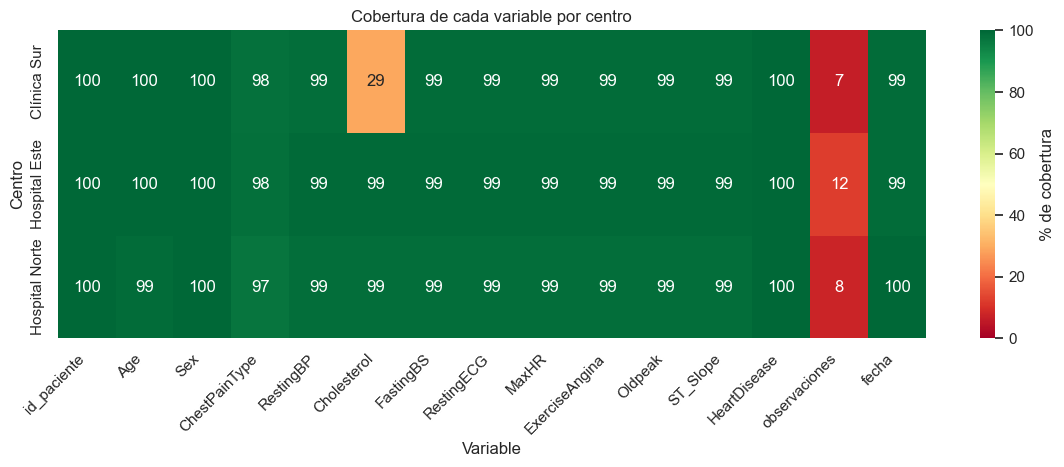

                pacientes  porcentaje_enfermos
centro                                        
Clínica Sur           244                 84.4
Hospital Este         381                 51.4
Hospital Norte        293                 36.2


In [80]:
# TODO: cobertura por centro, heatmap y pacientes por centro
cobertura_centro = datos_cobertura.groupby('centro', observed=True).agg(lambda s: s.notna().mean() * 100).astype(float)

plt.figure(figsize=(14, 4))
sns.heatmap(cobertura_centro, annot=True, fmt='.0f', cmap='RdYlGn', vmin=0, vmax=100,
            cbar_kws={'label': '% de cobertura'})
plt.title('Cobertura de cada variable por centro')
plt.xlabel('Variable')
plt.ylabel('Centro')
plt.xticks(rotation=45, ha='right')
plt.show()

pacientes_centro = limpio.groupby('centro', observed=True).agg(
    pacientes=('id_paciente', 'count'),
    porcentaje_enfermos=('HeartDisease', lambda s: round(s.mean() * 100, 1))
)
print(pacientes_centro)

**Parte C — Cobertura por registro.**

1. Calcula la cobertura de cada fila y dibuja su histograma con una línea en el umbral del 60 %.
2. Muestra las filas por debajo del umbral. ¿Qué tienen en común?
3. Repite el cálculo **sin** la columna `observaciones`. ¿Cambia mucho la distribución?

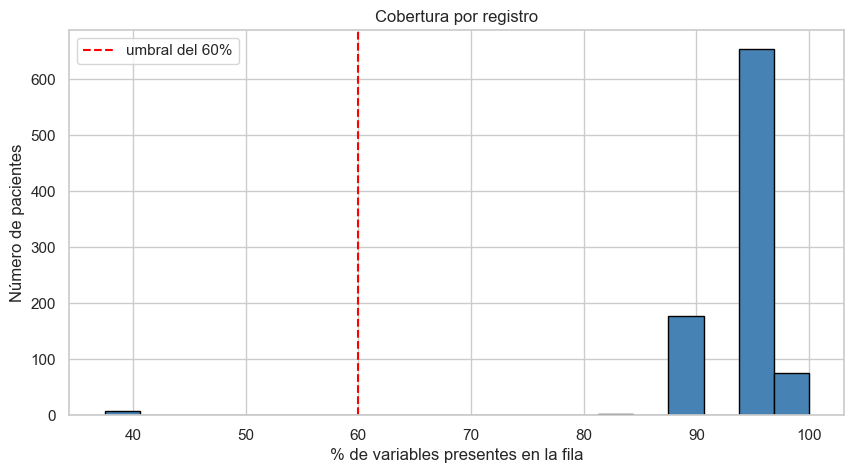

Filas por debajo del umbral: 8


,id_paciente,centro,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,observaciones,fecha
14,P0430,Clínica Sur,63,M,NaN,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,NaN,1,NaN,2024-01-22
153,P0648,Hospital Este,37,F,NaN,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,NaN,0,NaN,2025-05-23
243,P0114,Hospital Norte,38,M,NaN,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,NaN,0,NaN,2025-02-20
432,P0800,Hospital Este,53,M,NaN,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,NaN,0,NaN,2025-03-12
485,P0466,Clínica Sur,42,M,NaN,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,NaN,0,NaN,2025-09-12
628,P0082,Hospital Norte,54,M,NaN,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,NaN,0,NaN,2025-05-16
642,P0249,Hospital Norte,45,M,NaN,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,NaN,1,NaN,2025-09-09
829,P0270,Hospital Norte,47,F,NaN,<NA>,<NA>,<NA>,NaN,<NA>,NaN,NaN,NaN,0,NaN,2024-06-09



Cobertura por fila con observaciones:
count    918.0
mean      92.5
std        6.1
min       37.5
25%       93.8
50%       93.8
75%       93.8
max      100.0
dtype: float64
Cobertura por fila sin observaciones:
count    918.0
mean      98.1
std        6.1
min       40.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
dtype: float64
Filas por debajo del 60% sin observaciones: 8


In [81]:
# TODO: cobertura por registro
cob_fila = datos_cobertura.notna().mean(axis=1) * 100

plt.figure(figsize=(10, 5))
plt.hist(cob_fila, bins=20, color='steelblue', edgecolor='black')
plt.axvline(60, color='red', linestyle='--', label='umbral del 60%')
plt.title('Cobertura por registro')
plt.xlabel('% de variables presentes en la fila')
plt.ylabel('Número de pacientes')
plt.legend()
plt.show()

bajas = cob_fila < 60
print('Filas por debajo del umbral:', bajas.sum())
display(limpio.loc[bajas].drop(columns='revisar'))

# Sin la columna observaciones
cob_fila_sin_obs = datos_cobertura.drop(columns='observaciones').notna().mean(axis=1) * 100
print()
print('Cobertura por fila con observaciones:')
print(cob_fila.describe().round(1))
print('Cobertura por fila sin observaciones:')
print(cob_fila_sin_obs.describe().round(1))
print('Filas por debajo del 60% sin observaciones:', (cob_fila_sin_obs < 60).sum())

**Preguntas:**

1. ¿Qué variables quedan por debajo del 80 %? ¿Descartarías alguna? Ten en cuenta para qué sirve cada una.
2. `Cholesterol` está justo en el límite. Mirando la Parte B, ¿es un problema de una variable o de un **centro**? Si descartaras las filas sin colesterol, ¿qué le pasaría a la representación de cada centro en el dataset?
3. ¿Qué harías con los registros de la Parte C? Recuerda que conservan la variable objetivo.
4. **Completitud** y **cobertura** (en el sentido de «a quién representan los datos») no son lo mismo. Pon un ejemplo de este dataset en el que una variable esté completa al 100 % y, aun así, haya un problema de cobertura.

*Escribe aquí tus respuestas:*

1. Solo observaciones, con un 9,3%, porque es un comentario libre que se rellena cuando hace falta. La descartaría para el modelo porque no sirve para entrenar.
2. Es un problema de un centro, la Clínica Sur no tiene colesterol en 173 de sus 244 pacientes y en los otros dos casi no falta. Si descartara esas filas, la Clínica Sur se quedaría con muy pocos pacientes y además es la que más enfermos tiene.
3. Son 8 filas que solo tienen centro, fecha, edad, sexo y la variable objetivo. No rellenaría nada porque habría que inventar casi todo, las quitaría o le pediría los datos al centro. Sin observaciones la cobertura de las filas sube pero son las mismas 8
4. Por ejemplo Sex está completa al 100% y aun asi solo el 21% son mujeres.

## Ejercicio 2.6 — Comprobación final e informe de calidad

**Parte A — ¿Has limpiado bien?**
Los `id_paciente` corresponden, en orden, a las filas de `heart.csv`: `P0001` es la fila 0, `P0002` la fila 1, etc. Eso te permite **comprobar** tu limpieza contra el original (en un caso real no tendrías esta suerte).

1. Ordena `limpio` por `id_paciente` y alinea su índice con el de `heart_na` (sin la columna `chol_ausente`).
2. Para cada una de las 12 columnas de `heart.csv`, cuenta en cuántas filas tu valor **coincide** con el de `heart_na`, en cuántas **difiere** y en cuántas tú tienes un `NaN` que el original no tiene. Considera que dos `NaN` coinciden.
3. Muestra las filas en las que tu valor difiere del original.

In [82]:
# TODO: comparación de limpio con heart_na
limpio_ord = limpio.sort_values('id_paciente').reset_index(drop=True)
original = heart_na[heart.columns].reset_index(drop=True)

columnas_num = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease']

filas = {}
diferencias = []
for col in heart.columns:
    if col in columnas_num:
        mio = limpio_ord[col].astype('float64')
        orig = original[col].astype('float64')
    else:
        mio = limpio_ord[col].astype(object)
        orig = original[col].astype(object)

    ambos_nan = mio.isna() & orig.isna()
    coinciden = (mio == orig) | ambos_nan
    nan_mio = mio.isna() & orig.notna()
    difieren = ~coinciden & ~nan_mio

    filas[col] = {'coinciden': coinciden.sum(), 'difieren': difieren.sum(), 'NaN mio que no está en el original': nan_mio.sum()}
    if difieren.sum() > 0:
        diferencias.append(pd.DataFrame({'id_paciente': limpio_ord.loc[difieren, 'id_paciente'], 'columna': col,
                                         'mi_valor': mio[difieren], 'original': orig[difieren]}))

comparacion = pd.DataFrame(filas).T
print(comparacion)
print()
print('Filas en las que mi valor difiere del original:')
if diferencias:
    display(pd.concat(diferencias))
else:
    print('Ninguna')

                coinciden  difieren  NaN mio que no está en el original
Age                   915         0                                   3
Sex                   918         0                                   0
ChestPainType         898         0                                  20
RestingBP             910         0                                   8
Cholesterol           900        11                                   7
FastingBS             910         0                                   8
RestingECG            910         0                                   8
MaxHR                 910         0                                   8
ExerciseAngina        910         0                                   8
Oldpeak               910         0                                   8
ST_Slope              910         0                                   8
HeartDisease          918         0                                   0

Filas en las que mi valor difiere del original:


,id_paciente,columna,mi_valor,original
541,P0542,Cholesterol,112.0,113.0
542,P0543,Cholesterol,275.0,274.0
593,P0594,Cholesterol,259.0,258.0
615,P0616,Cholesterol,321.0,322.0
683,P0684,Cholesterol,244.0,242.0
685,P0686,Cholesterol,259.0,260.0
707,P0708,Cholesterol,267.0,266.0
768,P0769,Cholesterol,302.0,303.0
819,P0820,Cholesterol,290.0,289.0
843,P0844,Cholesterol,282.0,283.0


**Parte B — Exportar.**
Guarda `limpio` en `datos/heart_limpio.csv` (UTF-8, separador `,`, sin el índice) y `registro_cambios` en `datos/heart_registro_cambios.csv`. Vuelve a cargar `heart_limpio.csv` y comprueba que se lee bien con un `read_csv` sin parámetros. Aplica `informe_calidad(..., REGLAS)` del ejercicio 1.5 al fichero recargado.

In [83]:
# TODO: exportar, recargar y aplicar informe_calidad
limpio.to_csv(DATOS / 'heart_limpio.csv', index=False, encoding='utf-8', sep=',')
pd.DataFrame(registro_cambios).to_csv(DATOS / 'heart_registro_cambios.csv', index=False, encoding='utf-8', sep=',')

recargado = pd.read_csv(DATOS / 'heart_limpio.csv')
print('Dimensiones del fichero recargado:', recargado.shape)
print(recargado.dtypes)
display(recargado.head())

print()
display(informe_calidad(recargado, REGLAS))

Dimensiones del fichero recargado: (918, 17)
id_paciente        object
centro             object
Age               float64
Sex                object
ChestPainType      object
RestingBP         float64
Cholesterol       float64
FastingBS         float64
RestingECG         object
MaxHR             float64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
observaciones      object
revisar              bool
fecha              object
dtype: object


,id_paciente,centro,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,observaciones,revisar,fecha
0,P0173,Hospital Norte,53.0,M,ATA,140.0,320.0,0.0,Normal,162.0,N,0.0,Up,0,NaN,False,2025-10-31
1,P0160,Hospital Norte,54.0,M,ATA,160.0,195.0,0.0,ST,130.0,N,1.0,Up,0,NaN,False,2024-08-06
2,P0264,Hospital Norte,59.0,M,ASY,130.0,126.0,0.0,Normal,125.0,N,0.0,Flat,1,Pendiente de ecocardiografía,False,2025-05-18
3,P0664,Hospital Este,66.0,M,ATA,160.0,246.0,0.0,Normal,120.0,Y,0.0,Flat,1,NaN,False,2025-09-25
4,P0656,Hospital Este,40.0,M,ASY,152.0,223.0,0.0,Normal,181.0,N,0.0,Up,1,NaN,False,2024-12-09


,dtype,n_ausentes,pct_ausentes,n_atipicos_iqr,pct_atipicos_iqr,n_fuera_dominio
Age,float64,3,0.33,0,0.0,0
RestingBP,float64,9,0.98,27,2.94,0
Cholesterol,float64,179,19.5,23,2.51,0
FastingBS,float64,8,0.87,213,23.2,0
MaxHR,float64,8,0.87,2,0.22,0
Oldpeak,float64,8,0.87,16,1.74,0
HeartDisease,int64,0,0.0,0,0.0,0


**Parte C — Informe de calidad.**
Completa el informe con **todos** los problemas que has encontrado en `heart_sucio.csv`, agrupados por dimensión de calidad:

| Dimensión | Problema | Variable(s) | Filas afectadas | Cómo lo detectaste | Decisión tomada |
|---|---|---|---|---|---|
| **Unicidad** (duplicados) | Filas duplicadas exactas | Todas | 10 | duplicated() | Las quité |
| **Unicidad** (duplicados) | Pacientes reenviados con otro formato | centro, fecha_visita | 6 | Comparando filas con el mismo id | Primera aparición |
| **Unicidad** (duplicados) | Mismo paciente con MaxHR distinto | MaxHR | 2 | Comparando filas con el mismo id | Primera aparición y marcado en revisar |
| **Validez** (formato y dominio) | Unidades escritas en el número | Age, MaxHR | 6 y 18 | no_numericos | Las quité |
| **Validez** (formato y dominio) | Fechas imposibles y fechas futuras | fecha | 2 y 3 | to_datetime y FECHA_EXPORTACION | NaT |
| **Validez** (formato y dominio) | Valores fuera de rango | Age, RestingBP | 4 | fuera_de_dominio | Corregí los claros y el resto NaN |
| **Consistencia** (misma cosa, misma forma) | Texto escrito de muchas formas | centro, Sex, ChestPainType, RestingECG, ST_Slope | 124, 290, 30, 29 y 35 | value_counts | Normalizar y mapear |
| **Consistencia** (misma cosa, misma forma) | Sí, No, yes en lugar de códigos | FastingBS, ExerciseAngina | 621 y 272 | value_counts | Mapeo |
| **Consistencia** (misma cosa, misma forma) | Coma decimal y tres formatos de fecha | Oldpeak, fecha_visita | 326 y todas | Mirando los valores | limpiar_numero y to_datetime |
| **Exactitud** (¿el valor es el real?) | Colesterol en mmol/L | Cholesterol | 14 | Valores pequeños con decimales | Convertí a mg/dL |
| **Exactitud** (¿el valor es el real?) | Letra O en lugar de un cero | RestingBP | 1 | no_numericos | La corregí a 130 |
| **Completitud** (ausentes) | Colesterol ausente | Cholesterol | 179 | Informe de cobertura | NaN, se trata en la UD3 |
| **Completitud** (ausentes) | Filas casi vacías | Casi todas | 8 | Cobertura por registro | Sin decidir |
| **Completitud** (ausentes) | Observaciones casi siempre vacías | observaciones | 833 | Cobertura por variable | No usarla |
| **Codificación** (encoding, tipos) | Fichero en latin-1 y todo como texto | Todo | Todo | UnicodeDecodeError e info() | Cargar con latin-1 y convertir tipos |

Añade tantas filas como necesites.

**Preguntas:**

1. Según la Parte A, ¿en qué columnas te has quedado con valores distintos del original? ¿Se deben a errores tuyos o a decisiones razonables que no se podían tomar mejor?
2. ¿Qué problemas habrías sido **incapaz** de detectar sin tener el fichero original para comparar? ¿Qué te dice eso sobre los límites de la limpieza de datos?
3. ¿Qué le pedirías a cada centro para que la próxima exportación llegue sin estos problemas? Escribe al menos tres normas concretas.

*Escribe aquí tus respuestas:*

1. Solo en Cholesterol, en 11 filas, con una diferencia de 1 o 2 mg/dL. Eran valores en mmol/L con un decimal y al convertir y redondear no se recupera el valor exacto. No es un error mío, es una decision razonable.
2. No habría podido saber cuál de los dos MaxHR era el correcto en los pacientes repetidos, ni si una fecha como el 13 de mayo es la real porque parece válida. La limpieza arregla formatos y valores imposibles, pero no asegura que el dato sea exacto.
3. Que el fichero vaya en utf-8, que usen los mismos códigos y un solo formato de fecha, que las unidades sean siempre las mismas con punto decimal, que lo que falte se deje vacío y no con 0 o ?, y que cada paciente tenga un id único